<img src="https://images.seeklogo.com/logo-png/28/1/u-cayetano-heredia-logo-png_seeklogo-289967.png"
     alt="LOGO UPCH" width="250" align="right">

<br>

<h1><font color="#7F000E" size="5">UNIVERSIDAD PERUANA CAYETANO HEREDIA</font></h1>

<h1><font color="#7F000E" size="6">SEÑALES BIOMÉDICAS</font></h1>

<h1><font color="#7F000E" size="4">LABORATORIO 10 — SOLUCIONARIO: resultados explicados y respuestas</font></h1>

<br>

<div style="text-align:right">
  <font color="#7F000E" size="3">Ing. Alexander Valdez Portocarrero</font><br>
  <font color="#7F000E" size="3">Curso: Introducción a las Señales Biomédicas</font><br>
  <font color="#7F000E" size="3">Registro: MovimientoLeve_Pulgar.txt (BITalino, 04/09/2026)</font><br>
</div>

## Cómo leer este solucionario

Este cuaderno contiene **el laboratorio completo ya ejecutado**, con los resultados obtenidos sobre el registro real **`MovimientoLeve_Pulgar.txt`**. Después de cada resultado importante encontrarás tres tipos de celdas:

| Marca | Qué contiene |
|---|---|
| 📘 **Explicación** | Qué hizo la celda anterior y cómo leer su resultado, en lenguaje sencillo |
| ✅ **Respuesta** | Respuesta a las preguntas de verificación y a los ejercicios |
| 🔎 **Verificación adicional** | Pequeños cálculos extra para sustentar una respuesta con números (no estaban en el laboratorio original) |

**Regla de este solucionario:** toda cifra que aparece en las explicaciones sale de una salida de código visible en este cuaderno. Cuando una respuesta es **conceptual** (depende de la teoría y no de estos datos), se indica explícitamente.

### ⚠️ Cómo se adaptó el laboratorio a un solo registro

El laboratorio original usa **dos** archivos (BASELINE y PRUEBA con ~20 contracciones). Aquí solo se dispone de **un** registro de 19.05 s, en el que el pulgar permanece en reposo hasta ~17 s y después hay **un único movimiento leve** que dura hasta el final de la grabación. Por eso:

| Elemento del laboratorio | Cómo se resolvió con este registro |
|---|---|
| BASELINE (reposo/ruido) | Los **primeros 15 s** del mismo registro (antes del movimiento) |
| PRUEBA | El **registro completo** (0–19.05 s) |
| Ciclos reposo + contracción para la validación por grupos | **Bloques temporales de 0.6 s**, porque solo hay una contracción (`StratifiedGroupKFold`, 3 pliegues) |
| Ejercicio 2 (fatiga entre contracciones) | Tendencia **dentro** de la única contracción, en segmentos consecutivos de 250 ms |

**Consecuencia importante:** solo hay **13 ventanas de contracción** (todas de la misma contracción), frente a 136 de reposo. Los puntajes de clasificación son por eso muy poco informativos (ver Bloque 6) y se interpretan con cautela.

### Resumen de resultados clave

| Aspecto | Resultado obtenido |
|---|---|
| Frecuencia de muestreo / resolución | 1000 Hz / 10 bits |
| Duración | Registro completo 19.05 s · BASELINE (0–15 s) |
| Rango medible del sensor | ±1.632 mV (1 cuenta ADC = 3.19 µV) |
| Amplitud de la señal | ADC entre 479 y 548 (−0.105 a +0.115 mV), solo ~7 % del rango |
| Muestras saturadas | **0** (0.000 %) |
| Piso de ruido (RMS del baseline filtrado) | 6.72 µV |
| SNR aproximada (movimiento vs. baseline) | 11.7 dB |
| Contracciones detectadas | **1**, de 17.21 a 19.05 s (1.84 s; termina donde termina el registro) |
| Ventanas de 250 ms | 151 (136 reposo · 13 contracción · 2 transición) |
| Característica más discriminante (Fisher) | SSC (35.77), seguida de WAMP (32.94) y ZC (32.02) |
| Mejor resultado de clasificación | Un **solo umbral en RMS**: 1.000 de exactitud balanceada (ver cautelas en el Bloque 6) |
| LDA / SVM con todas las características | 1.000 / 0.933 |
| CNN con espectrogramas | 1.000 ± 0.000 (146 espectrogramas, solo 12 de contracción) |
| ¿Evidencia de fatiga? | No (con 6 segmentos de 250 ms, todos los p > 0.46) |


## Pregunta guía del laboratorio

> **¿Cómo convierte un dispositivo la actividad eléctrica de un músculo en números que puede entender?**

Una prótesis mioeléctrica, un exoesqueleto de rehabilitación o un sistema que detecta fatiga en un trabajador **no "miran" la señal cruda**: la resumen en un conjunto pequeño de números llamados **características** (*features*). Elegir y calcular bien esas características es, muchas veces, más importante que el clasificador que viene después.

### Objetivos de aprendizaje
Al terminar este laboratorio podrás:

1. Explicar el **origen fisiológico** de la sEMG y sus rangos típicos de amplitud y frecuencia.
2. **Convertir, filtrar y evaluar la calidad** de una señal real adquirida con BITalino.
3. **Segmentar** la señal en ventanas y **etiquetar** automáticamente reposo y contracción.
4. Calcular e interpretar características **temporales, estadísticas y espectrales**.
5. Construir una **matriz de características** y entrenar un clasificador **sin fuga de datos**.
6. Entender cómo una **CNN** aprende características a partir del **espectrograma (STFT)** y compararla con el enfoque clásico.

### Agenda (120 min)

| Bloque | Tiempo | Tipo |
|---|---|---|
| 0. Introducción y configuración | 5 min | Motivación |
| 1. Fundamentos fisiológicos | 15 min | Teoría + simulación |
| 2. Instrumentación y adquisición | 10 min | Técnica + práctica |
| 3. Preprocesamiento | 15 min | Práctica |
| 4. Segmentación y etiquetado | 10 min | Técnica + práctica |
| 5. Extracción de características clásicas | 25 min | Teoría + práctica |
| 6. Del vector de características al clasificador | 15 min | Práctica |
| 7. Deep learning: espectrograma + CNN | 15 min | Teoría + demo |
| 8. Ejercicios, cierre y referencias | 10 min | Síntesis |

**Datos del laboratorio:** un registro del movimiento leve del pulgar tomado con BITalino:
- `MovimientoLeve_Pulgar.txt` — 19.05 s: **reposo** (primeros ~17 s) seguido de **un movimiento leve** hasta el final del registro.

El BASELINE (referencia de ruido) se toma de los primeros 15 s de ese mismo registro y la PRUEBA es el registro completo. Si no tienes el archivo, el cuaderno genera automáticamente una **señal simulada** equivalente para que puedas seguir todo el flujo.


## 0. Configuración del entorno

Todas las bibliotecas usadas vienen preinstaladas en Google Colab (`numpy`, `scipy`, `pandas`, `matplotlib`, `scikit-learn`, `torch`). No es necesario `opensignalsreader`: escribiremos nuestro propio lector para **entender** el formato del archivo.

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from scipy.stats import kurtosis, skew

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.random.seed(42)

plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})
COLOR_REPOSO, COLOR_CONTRAC, COLOR_UPCH = "#4C72B0", "#C44E52", "#7F000E"

try:
    from IPython.display import display
except ImportError:
    display = print

print("Entorno listo.")

Entorno listo.


📘 **Explicación.** Esta celda solo prepara el entorno: importa las bibliotecas, fija una semilla aleatoria (`np.random.seed(42)`) para que la simulación salga igual cada vez y define los colores de las gráficas. El mensaje *"Entorno listo."* confirma que todo se cargó sin errores.

---
# 1. Fundamentos fisiológicos (15 min)

### 1.1 La unidad motora
El músculo no se contrae "en bloque". Se organiza en **unidades motoras (UM)**: una **motoneurona** de la médula espinal y **todas las fibras musculares que inerva**. Cuando la motoneurona dispara, todas sus fibras se despolarizan casi a la vez y producen un **potencial de acción de unidad motora (MUAP)**: una forma de onda bifásica o trifásica de pocos milisegundos.

El sistema nervioso regula la fuerza con dos mecanismos:

| Mecanismo | Qué ocurre | Efecto en la sEMG |
|---|---|---|
| **Reclutamiento** | Se activan más unidades motoras (primero las pequeñas — *principio de Henneman*) | Aumenta la amplitud |
| **Codificación por frecuencia** | Cada UM dispara más rápido (≈ 8 a 30 disparos/s) | Aumenta amplitud y densidad de la señal |

### 1.2 ¿Qué registra un electrodo de superficie?
Un electrodo sobre la piel no ve una UM aislada: ve la **suma espacial y temporal** de los MUAPs de muchas unidades, filtrada por grasa, piel y la propia distancia. El resultado es un **patrón de interferencia** que parece ruido aleatorio, pero cuya **amplitud** y **contenido espectral** codifican información sobre la activación muscular.

> 💡 **Idea clave:** la sEMG es como escuchar un estadio lleno desde afuera. No entiendes a ninguna persona en particular, pero sí sabes si hay pocos o muchos gritando (amplitud) y si las voces son agudas o graves (frecuencia).

### 1.3 Rangos típicos de la sEMG

| Propiedad | Valor típico |
|---|---|
| Amplitud | 0 – 10 mV pico a pico (en reposo: microvoltios) |
| Banda útil | ≈ 10 / 20 – 450 / 500 Hz |
| Energía dominante | ≈ 50 – 150 Hz |
| Distribución de amplitudes | Aproximadamente gaussiana de media cero en contracción sostenida |

Factores que la modifican: grosor del tejido adiposo, posición y distancia entre electrodos, temperatura, **fatiga** (desplaza el espectro a frecuencias más bajas), impedancia piel-electrodo y artefactos.

Veamos cómo surge el patrón de interferencia con una **simulación** simple.

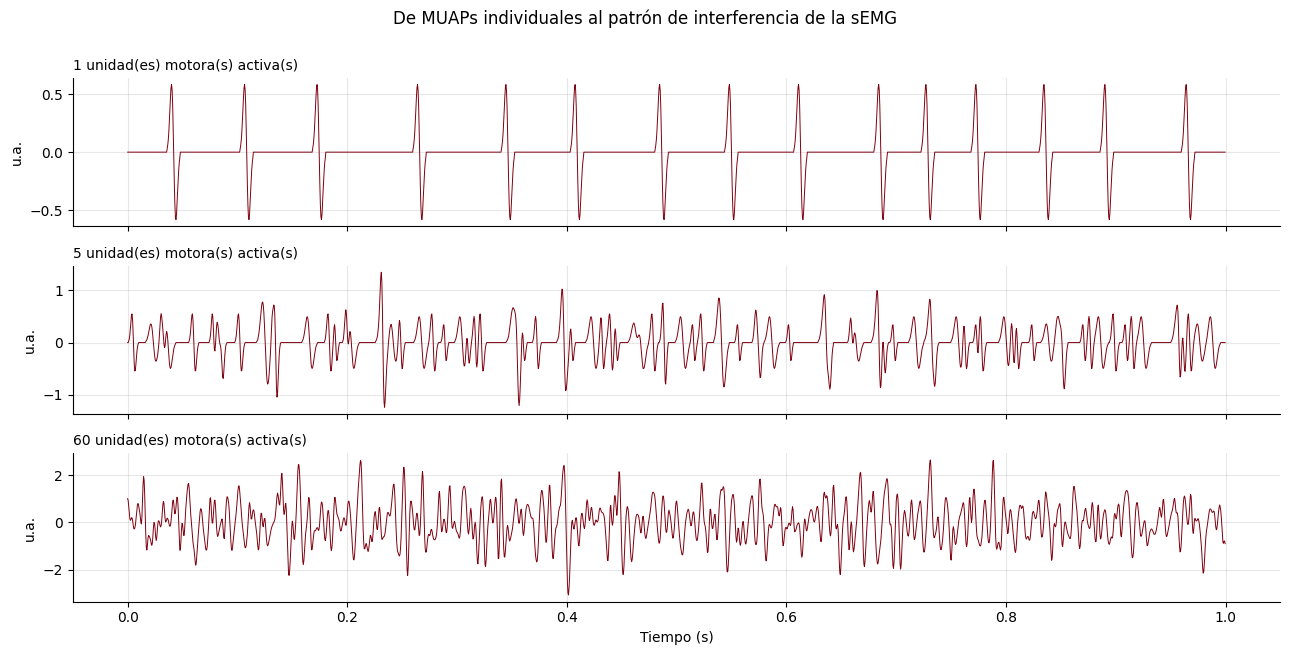

In [2]:
# Simulación didáctica: suma de trenes de MUAPs
FS_SIM = 2000
t_sim = np.arange(0, 1.0, 1/FS_SIM)

def muap(duracion_ms=10, fs=FS_SIM):
    # Forma bifásica tipo "derivada de gaussiana" (modelo simplificado de MUAP)
    tt = np.arange(-duracion_ms/2, duracion_ms/2, 1000/fs) / 1000
    s = duracion_ms / 1000 / 6
    return -tt / s * np.exp(-tt**2 / (2*s**2))

def tren_um(fr_hz, amplitud, dur_ms, fs=FS_SIM, n=len(t_sim)):
    # Una unidad motora disparando a ~fr_hz con variabilidad del 20 % entre disparos
    x = np.zeros(n); k = np.random.uniform(0, 1/fr_hz)
    while k < n/fs:
        x[int(k*fs)] = 1
        k += np.random.normal(1/fr_hz, 0.2/fr_hz)
    return amplitud * np.convolve(x, muap(dur_ms, fs), mode="same")

fig, ax = plt.subplots(3, 1, figsize=(13, 6.5), sharex=True)
for a, n_um in zip(ax, [1, 5, 60]):
    total = sum(tren_um(np.random.uniform(8, 25), np.random.uniform(0.2, 1.0),
                        np.random.uniform(6, 14)) for _ in range(n_um))
    a.plot(t_sim, total, lw=0.7, color=COLOR_UPCH)
    a.set_title(f"{n_um} unidad(es) motora(s) activa(s)", loc="left", fontsize=10)
    a.set_ylabel("u.a.")
ax[-1].set_xlabel("Tiempo (s)")
plt.suptitle("De MUAPs individuales al patrón de interferencia de la sEMG", y=1.0)
plt.tight_layout(); plt.show()

📘 **Explicación.** La simulación construye la sEMG "desde abajo":
1. Se crea la forma de **un** MUAP (una onda que sube y baja en pocos milisegundos).
2. Cada unidad motora "dispara" ese MUAP entre 8 y 25 veces por segundo, con algo de irregularidad.
3. Se **suman** los trenes de 1, 5 y 60 unidades motoras.

En la gráfica de arriba (1 UM) se ven picos separados y regulares, uno por cada disparo. En la del medio (5 UM) los picos empiezan a mezclarse. En la de abajo (60 UM) ya no se distingue ningún disparo: la señal parece ruido. Además, el eje vertical crece de una gráfica a otra: **más unidades activas producen más amplitud**.

> ❓ **Preguntas de verificación**
> 1. Con 1 unidad motora, ¿puedes distinguir cada disparo? ¿Y con 60?
> 2. ¿Qué mecanismo fisiológico representa pasar de 5 a 60 unidades?
> 3. Si la señal con 60 UM "parece ruido", ¿por qué sigue siendo útil? ¿Qué cambia entre las tres gráficas que sí podríamos medir?

✅ **Respuestas**

1. **Con 1 UM, sí:** cada disparo aparece como un pico aislado, separado del siguiente. **Con 60 UM, no:** los MUAPs se superponen en el tiempo y forman un patrón continuo (patrón de interferencia) donde ningún disparo individual es reconocible.
2. Representa el **reclutamiento**: el sistema nervioso activa más unidades motoras para producir más fuerza.
3. Aunque no podamos ver cada disparo, la señal sigue llevando información en **propiedades globales** que sí se pueden medir. La principal es la **amplitud**: en la figura, el rango del eje vertical crece al pasar de 1 a 5 y a 60 UM, y eso lo captura una medida como el RMS. También cambia la **densidad** de la señal (cuántas veces sube y baja por segundo), que capturan medidas como los cruces por cero. Esas propiedades son justamente las **características** que calcularemos en el Bloque 5.

---
# 2. Instrumentación y adquisición (10 min)

### 2.1 Cadena de adquisición del BITalino
```
Músculo → electrodos Ag/AgCl → amplificador diferencial (G = 1009) → filtro analógico → ADC 10 bits → Bluetooth → OpenSignals (.txt)
```

- **Configuración bipolar / diferencial:** dos electrodos sobre el vientre muscular y uno de referencia en zona eléctricamente neutra (hueso). El amplificador **resta** ambos electrodos: lo que es común a los dos (p. ej., interferencia de la red eléctrica) se cancela (*rechazo en modo común*, CMRR).
- **Colocación:** recomendaciones **SENIAM** — electrodos alineados con las fibras, entre el punto motor y el tendón, con ~20 mm entre centros; piel limpia para reducir la impedancia.

### 2.2 Muestreo y cuantización
- **Frecuencia de muestreo:** el archivo indica **Fs = 1000 Hz** → frecuencia de Nyquist = 500 Hz. Cubre la banda útil de la sEMG.
- **Resolución:** 10 bits → el ADC entrega enteros de **0 a 1023**. El valor ~512 corresponde a 0 V.

### 2.3 Conversión de unidades (hoja técnica del sensor EMG BITalino)

$$
\text{EMG}_{mV} = \frac{\left(\dfrac{ADC}{2^{n}} - \dfrac{1}{2}\right)\cdot V_{CC}}{G_{EMG}} \times 1000,
\qquad V_{CC}=3.3\ \text{V},\ G_{EMG}=1009,\ n = 10
$$

Esto da un rango de medición de aproximadamente **±1.64 mV**. Cualquier actividad mayor **satura** el ADC (se queda pegada en 0 o en 1023).

### 2.4 Fuentes de ruido y artefactos

| Fuente | Característica | Cómo se trata |
|---|---|---|
| Red eléctrica | 60 Hz en Perú (y armónicos) | Diferencial + filtro *notch* |
| Movimiento de electrodos/cables | < 20 Hz, gran amplitud | Pasa-altos ≈ 20 Hz, buena fijación |
| ECG (cerca del tórax) | Picos periódicos ~1 Hz | Pasa-altos, ubicación |
| Ruido térmico/electrónico | Banda ancha, bajo nivel | Se estima con un registro en reposo |
| **Saturación (clipping)** | Señal "aplanada" en el máximo/mínimo del ADC | Prevención (ganancia) y detección |

> 💡 **Idea clave:** ningún filtro digital recupera información que se perdió por saturación. La calidad empieza en la adquisición.

### 2.5 Carga del archivo

El formato de texto de OpenSignals tiene tres partes:
1. Línea `# OpenSignals Text File Format`.
2. Línea `# {...}` con un **JSON** de metadatos: frecuencia de muestreo, resolución, sensores, nombres de columnas.
3. `# EndOfHeader` y luego los datos en columnas separadas por tabulaciones (`nSeq`, entradas digitales, `A1`...).

Escribimos un lector que **lee los metadatos del propio archivo** en lugar de suponerlos.

**En Colab:** ejecuta la celda siguiente; si el archivo no está en la carpeta, se abrirá un diálogo para subirlo.

**Un solo archivo:** como solo tenemos `MovimientoLeve_Pulgar.txt`, el **BASELINE** se toma de sus primeros **15 s** (el pulgar está en reposo) y la **PRUEBA** es el registro completo.


In [3]:
RUTA_SENAL = "MovimientoLeve_Pulgar.txt"

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and not os.path.exists(RUTA_SENAL):
    from google.colab import files
    print("Sube el archivo MovimientoLeve_Pulgar.txt")
    files.upload()

USAR_SIMULADA = not os.path.exists(RUTA_SENAL)
print("Usando señal", "SIMULADA" if USAR_SIMULADA else "REAL (BITalino)")


Usando señal REAL (BITalino)


📘 **Explicación.** La celda buscó el archivo `MovimientoLeve_Pulgar.txt` en la carpeta de trabajo. Como lo encontró, el cuaderno trabaja con la **señal real del BITalino**, no con la simulada.

In [4]:
def leer_opensignals(ruta, etiqueta_canal="A1"):
    # Lee un TXT de OpenSignals y devuelve (valores ADC del canal, diccionario de metadatos)
    with open(ruta, "r", encoding="utf-8") as f:
        cabecera = [next(f) for _ in range(3)]
    meta = list(json.loads(cabecera[1].lstrip("# ").strip()).values())[0]
    datos = np.loadtxt(ruta, comments="#")
    idx_col = meta["column"].index(etiqueta_canal)
    idx_res = meta["column"].index(etiqueta_canal)
    meta["bits"] = meta["resolution"][idx_res]
    return datos[:, idx_col].astype(float), meta


def simular_registros(fs=1000, n_bits=10):
    # Plan B: genera baseline + prueba con contracciones cada ~3 s (en cuentas ADC)
    rng = np.random.default_rng(0)
    def a_adc(mv):
        adc = (mv / 1000 * 1009 / 3.3 + 0.5) * 2**n_bits
        return np.clip(np.round(adc), 0, 2**n_bits - 1)
    base = 0.006 * rng.standard_normal(69 * fs)
    t = np.arange(63 * fs) / fs
    prueba = 0.025 * rng.standard_normal(len(t))
    for k, ini in enumerate(np.arange(1.5, 61, 3.0)):
        idx = (t >= ini) & (t < ini + 1.2)
        env = np.hanning(idx.sum())
        b, a = signal.butter(2, [40, 200], "bandpass", fs=fs)
        ruido = signal.lfilter(b, a, rng.standard_normal(idx.sum()))
        prueba[idx] += (0.9 - 0.01 * k) * env * ruido / ruido.std() * 0.5
    meta = {"sampling rate": fs, "bits": n_bits, "sensor": ["EMG simulado"], "date": "-", "time": "-"}
    return a_adc(base), dict(meta), a_adc(prueba), dict(meta)


# Este laboratorio se resuelve con UN solo registro: MovimientoLeve_Pulgar.txt.
# Como no hay un archivo BASELINE aparte, el REPOSO se toma de la parte inicial del mismo registro
# (antes de que empiece el movimiento) y la PRUEBA es el registro completo.
T_REPOSO_S = 15.0     # segundos iniciales que se usan como baseline (el movimiento empieza después de ~17 s)

if USAR_SIMULADA:
    adc_base, meta_base, adc_prueba, meta_prueba = simular_registros()
else:
    adc_prueba, meta_prueba = leer_opensignals(RUTA_SENAL)
    meta_base = dict(meta_prueba)
    adc_base = adc_prueba[: int(T_REPOSO_S * int(meta_prueba["sampling rate"]))]

FS = int(meta_prueba["sampling rate"])
N_BITS = int(meta_prueba["bits"])
assert FS == int(meta_base["sampling rate"]), "Los registros tienen Fs distintas."

for nombre, adc, meta in [("BASELINE (0–15 s)", adc_base, meta_base), ("REGISTRO COMPLETO", adc_prueba, meta_prueba)]:
    print(f"{nombre:18s} | sensor: {meta['sensor'][0]:11s} | fecha: {meta['date']} {meta['time']} | "
          f"Fs = {meta['sampling rate']} Hz | {meta['bits']} bits | "
          f"{len(adc):,} muestras = {len(adc)/FS:.1f} s | ADC min/max: {adc.min():.0f}/{adc.max():.0f}")


BASELINE (0–15 s)  | sensor: EMGBITREV   | fecha: 2026-9-4 15:29:3.749 | Fs = 1000 Hz | 10 bits | 15,000 muestras = 15.0 s | ADC min/max: 501/524
REGISTRO COMPLETO  | sensor: EMGBITREV   | fecha: 2026-9-4 15:29:3.749 | Fs = 1000 Hz | 10 bits | 19,050 muestras = 19.1 s | ADC min/max: 479/548


In [5]:
N_BITS

10

📘 **Explicación.** El lector leyó la cabecera JSON del archivo y obtuvo los metadatos **del propio registro**, sin suponer nada:

- Sensor **EMGBITREV**, **Fs = 1000 Hz**, **10 bits** (valores de 0 a 1023). Grabación del **04/09/2026 a las 15:29:03**.
- **BASELINE (primeros 15 s):** 15 000 muestras. El ADC solo varió entre **501 y 524**, apenas 24 cuentas alrededor del centro (~512). Es lo esperable en reposo: casi no hay señal.
- **Registro completo:** 19 050 muestras (19.05 s). El ADC varió entre **479 y 548**, es decir, 70 cuentas: **muy lejos de los extremos 0 y 1023**. No hay señales de saturación.
- Como el baseline y la prueba salen del **mismo archivo**, se grabaron en las mismas condiciones (mismos electrodos, misma piel, mismo instante). Esto será útil en el Bloque 4.


Rango medible del sensor: ±1.632 mV
Resolución (1 cuenta ADC): 0.0032 mV = 3.19 µV


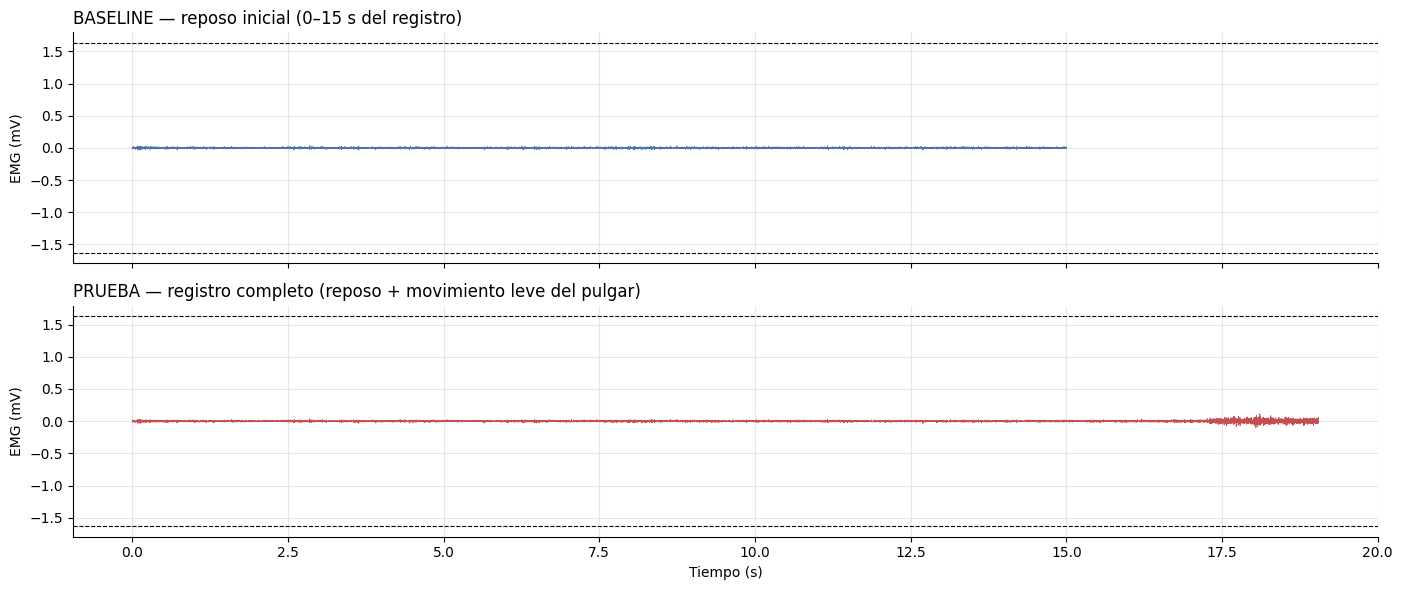

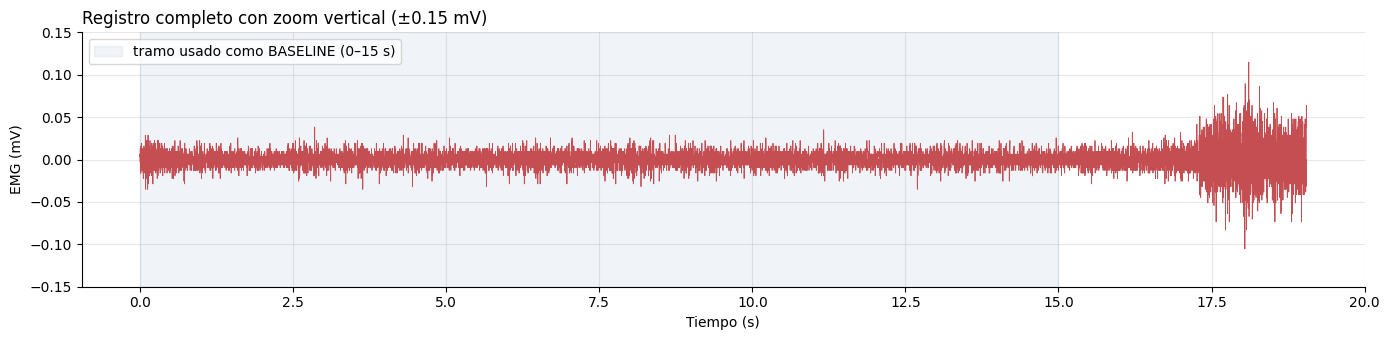

In [6]:
VCC, G_EMG = 3.3, 1009

def adc_a_mV(adc, n_bits=N_BITS, vcc=VCC, ganancia=G_EMG):
    return ((adc / 2**n_bits) - 0.5) * vcc / ganancia * 1000

emg_base_mV   = adc_a_mV(adc_base)
emg_prueba_mV = adc_a_mV(adc_prueba)
t_base   = np.arange(len(emg_base_mV)) / FS
t_prueba = np.arange(len(emg_prueba_mV)) / FS

rango_max = adc_a_mV(2**N_BITS - 1)
print(f"Rango medible del sensor: ±{rango_max:.3f} mV")
print(f"Resolución (1 cuenta ADC): {adc_a_mV(513) - adc_a_mV(512):.4f} mV = "
      f"{(adc_a_mV(513) - adc_a_mV(512))*1000:.2f} µV")

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True, sharey=True)
ax[0].plot(t_base, emg_base_mV, lw=0.5, color=COLOR_REPOSO)
ax[0].set_title("BASELINE — reposo inicial (0–15 s del registro)", loc="left")
ax[1].plot(t_prueba, emg_prueba_mV, lw=0.5, color=COLOR_CONTRAC)
ax[1].set_title("PRUEBA — registro completo (reposo + movimiento leve del pulgar)", loc="left")
for a in ax:
    a.axhline(rango_max, ls="--", color="k", lw=0.8); a.axhline(-rango_max, ls="--", color="k", lw=0.8)
    a.set_ylabel("EMG (mV)")
ax[1].set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()

# Mismo registro con zoom vertical (el rango completo de ±1.6 mV hace ver la señal casi plana)
fig, ax = plt.subplots(1, 1, figsize=(14, 3.5))
ax.plot(t_prueba, emg_prueba_mV, lw=0.6, color=COLOR_CONTRAC)
ax.axvspan(0, len(emg_base_mV)/FS, color=COLOR_REPOSO, alpha=0.08, label="tramo usado como BASELINE (0–15 s)")
ax.set_ylim(-0.15, 0.15); ax.set_xlabel("Tiempo (s)"); ax.set_ylabel("EMG (mV)")
ax.set_title("Registro completo con zoom vertical (±0.15 mV)", loc="left"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()


📘 **Explicación.** Se convirtieron las cuentas del ADC a milivoltios con la fórmula del fabricante.

- **Rango medible: ±1.632 mV.** Es lo máximo que el sensor puede representar (líneas punteadas de la primera figura).
- **Resolución: 3.19 µV por cuenta.** Es el cambio de voltaje más pequeño que el sistema distingue.
- La señal real es **muy pequeña frente al rango**: va de −0.105 a +0.115 mV (alrededor del 7 % del rango). Por eso en la primera figura (con las líneas de ±1.632 mV) todo parece una línea plana; la segunda figura repite el registro con un **zoom vertical de ±0.15 mV**.
- En el zoom se ve un **reposo con ruido de amplitud casi constante hasta ~17 s** y, después, una **ráfaga de actividad más grande que dura hasta el final del registro** (19.05 s): es el movimiento leve del pulgar. No hay ráfagas repetidas, solo una.
- Con una señal tan pequeña, la **cuantización** pesa: el ruido del baseline ocupa pocas cuentas y la actividad del movimiento unas ~8 cuentas de RMS (25 µV / 3.19 µV).


### 2.6 Control de calidad: ¿hay saturación?
Una muestra está saturada si su valor ADC es exactamente 0 o $2^n-1$. Es importante **cuantificarlo** antes de calcular características, porque recorta los picos y distorsiona sobre todo las medidas sensibles a los extremos (curtosis, varianza).

In [7]:
sat_prueba = (adc_prueba <= 0) | (adc_prueba >= 2**N_BITS - 1)
sat_base   = (adc_base   <= 0) | (adc_base   >= 2**N_BITS - 1)
print(f"Saturación BASELINE: {sat_base.sum()} muestras ({100*sat_base.mean():.3f} %)")
print(f"Saturación PRUEBA  : {sat_prueba.sum()} muestras ({100*sat_prueba.mean():.3f} %)")

if sat_prueba.any():
    i0 = np.flatnonzero(sat_prueba)[0]
    sl = slice(max(0, i0 - 150), i0 + 150)
    plt.figure(figsize=(12, 3))
    plt.plot(t_prueba[sl], emg_prueba_mV[sl], lw=0.9, color=COLOR_CONTRAC)
    plt.plot(t_prueba[sl][sat_prueba[sl]], emg_prueba_mV[sl][sat_prueba[sl]], "ko", ms=3, label="saturada")
    plt.title("Zoom a un evento de saturación"); plt.xlabel("Tiempo (s)"); plt.ylabel("mV"); plt.legend()
    plt.show()

Saturación BASELINE: 0 muestras (0.000 %)
Saturación PRUEBA  : 0 muestras (0.000 %)


📘 **Explicación.** Una muestra se consideró saturada si su valor ADC era exactamente 0 o 1023.

- **BASELINE:** 0 muestras saturadas, como era de esperar en reposo.
- **Registro completo:** también **0 muestras saturadas (0.000 %)**.
- Como no hay ninguna, la celda **no dibuja el zoom** a un evento de saturación (solo lo hace cuando existe alguna muestra saturada).

La celda siguiente comprueba si el criterio «0 o 1023» es suficiente mirando los valores extremos que realmente aparecen.


🔎 **Verificación adicional — ¿dónde se "pega" realmente el ADC?**

La celda siguiente cuenta cuántas veces aparece cada valor extremo del ADC en la PRUEBA.

In [8]:

# Verificación adicional: ¿en qué valores se "pega" realmente el ADC?
valores, cuentas = np.unique(adc_prueba, return_counts=True)
print("5 valores ADC más bajos :", [(int(v), int(c)) for v, c in zip(valores[:5], cuentas[:5])])
print("5 valores ADC más altos :", [(int(v), int(c)) for v, c in zip(valores[-5:], cuentas[-5:])])

# Criterio corregido: también se cuenta el valor 1022 (2^n - 2), donde se observa la meseta superior
sat_corr = (adc_prueba <= 0) | (adc_prueba >= 2**N_BITS - 2)
n_win_250 = int(0.25 * FS)
ini_250 = np.arange(0, len(adc_prueba) - n_win_250 + 1, n_win_250 // 2)
print(f"\nCriterio original (0 o 1023)       : {sat_prueba.sum()} muestras ({100*sat_prueba.mean():.3f} %)")
print(f"Criterio corregido (0, 1022 o 1023): {sat_corr.sum()} muestras ({100*sat_corr.mean():.3f} %)")
print(f"Ventanas de 250 ms con saturación (criterio corregido): "
      f"{sum(sat_corr[i:i+n_win_250].any() for i in ini_250)}")


5 valores ADC más bajos : [(479, 1), (486, 3), (489, 5), (490, 1), (491, 3)]
5 valores ADC más altos : [(535, 3), (536, 1), (539, 1), (540, 1), (548, 1)]

Criterio original (0 o 1023)       : 0 muestras (0.000 %)
Criterio corregido (0, 1022 o 1023): 0 muestras (0.000 %)
Ventanas de 250 ms con saturación (criterio corregido): 0


📘 **Resultado de la verificación.** Los valores más bajos del ADC son 479, 486, 489, 490 y 491 (aparecen entre 1 y 5 veces cada uno) y los más altos 535, 536, 539, 540 y 548 (entre 1 y 3 veces). **No hay "amontonamiento" en ningún extremo**: el ADC nunca se acerca a 0 ni a 1023.

- Con el criterio del laboratorio (0 o 1023): **0 muestras (0.000 %)**.
- Con el criterio ampliado (0, 1022 o 1023): **0 muestras (0.000 %)** y **0 ventanas** de 250 ms afectadas.

**Consecuencia práctica:** en este registro la saturación **no es un problema**, y los dos criterios dan el mismo resultado. En los Bloques 5.7 y en el Ejercicio 1 las comparaciones «con saturación / sin saturación» no pueden mostrar diferencias, porque no hay ventanas saturadas.


> ❓ **Preguntas de verificación**
> 1. ¿Qué porcentaje de muestras está saturado? ¿Te parece aceptable?
> 2. ¿Qué cambiarías en la adquisición para evitarlo?
> 3. ¿Por qué el baseline sirve como "registro de ruido" del sistema?

✅ **Respuestas**

1. **0 %** (0 de 19 050 muestras), con cualquiera de los dos criterios. Es perfectamente aceptable. El problema de este registro es el contrario: la señal usa solo ~7 % del rango (−0.105 a +0.115 mV), así que la resolución de 3.19 µV por cuenta pesa más.
2. *(Respuesta conceptual.)* **No hay saturación que evitar.** Lo que convendría mejorar es la **relación señal-ruido** (11.7 dB, Bloque 3): colocar bien los electrodos sobre el vientre del músculo que mueve el pulgar (SENIAM), limpiar la piel, y pedir una contracción algo más intensa y **controlada** (por ejemplo, un % de la contracción máxima), con varias repeticiones y un registro más largo. La ganancia del BITalino es fija (G = 1009).
3. En el baseline el pulgar está en reposo, así que casi no hay actividad muscular voluntaria. Lo que queda registrado es lo que el sistema "mide sin señal": ruido electrónico, ruido de la interfaz piel-electrodo y posible interferencia. Por eso sirve como **piso de ruido**: el ADC solo varió 24 cuentas (501–524) y, tras filtrar, su RMS fue de **6.72 µV** (Bloque 3). *Ventaja de este registro:* el baseline son los primeros 15 s del mismo archivo, así que describe el ruido **en las mismas condiciones** de la prueba. *Limitación:* no es un registro independiente.


---
# 3. Preprocesamiento (15 min)

### 3.1 ¿Qué queremos eliminar?
1. **Componente continua (offset)** y derivas lentas → el pasa-altos lo resuelve.
2. **Artefactos de movimiento** (< 20 Hz).
3. **Ruido de alta frecuencia** por encima de la banda útil.
4. **Interferencia de 60 Hz** de la red eléctrica.

### 3.2 Diseño de filtros
- **Pasa-banda Butterworth 20–450 Hz, orden 4:** respuesta plana en la banda de paso. Se implementa en forma **SOS** (*second-order sections*) por estabilidad numérica.
- **Notch IIR en 60 Hz, Q = 30:** elimina una banda angosta (~2 Hz) alrededor de 60 Hz.
- **Filtrado de fase cero (`sosfiltfilt` / `filtfilt`):** filtra hacia adelante y hacia atrás, sin desfase. Válido para análisis **offline**; un sistema en tiempo real (prótesis) usaría filtros causales.

> ⚠️ Condición obligatoria: $0 < f_{baja} < f_{alta} < F_s/2$.

Antes de filtrar, miremos el **espectro** (densidad espectral de potencia, PSD) estimado con el **método de Welch**, que promedia periodogramas de segmentos solapados y da una estimación más estable que una sola FFT.

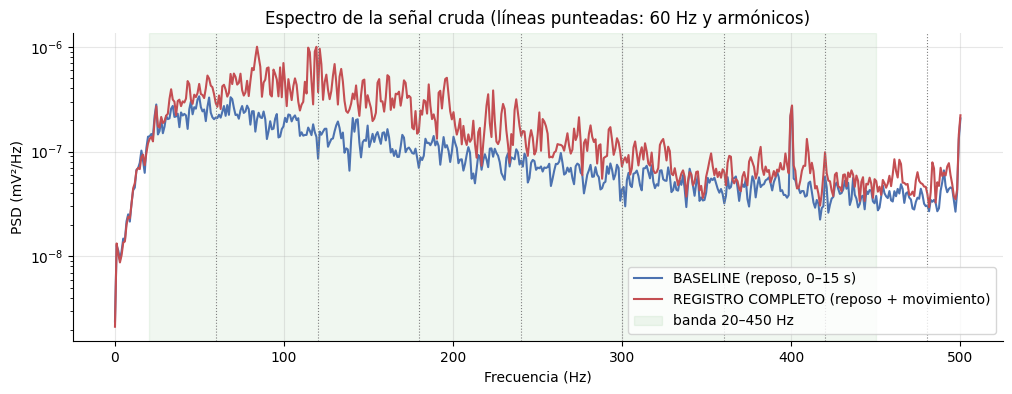

In [9]:
def psd(x, fs=FS, nperseg=1024):
    return signal.welch(x - np.mean(x), fs=fs, nperseg=nperseg)

f_b, P_b = psd(emg_base_mV)
f_p, P_p = psd(emg_prueba_mV)

plt.figure(figsize=(12, 4))
plt.semilogy(f_b, P_b, label="BASELINE (reposo, 0–15 s)", color=COLOR_REPOSO)
plt.semilogy(f_p, P_p, label="REGISTRO COMPLETO (reposo + movimiento)", color=COLOR_CONTRAC)
for k in range(1, 9):
    plt.axvline(60*k, color="gray", ls=":", lw=0.8)
plt.axvspan(20, 450, color="green", alpha=0.06, label="banda 20–450 Hz")
plt.xlabel("Frecuencia (Hz)"); plt.ylabel("PSD (mV²/Hz)")
plt.title("Espectro de la señal cruda (líneas punteadas: 60 Hz y armónicos)")
plt.legend(); plt.show()



###**La PSD por el método de Welch (Power Spectral Density)**

La PSD por el método de Welch (Power Spectral Density) permite conocer cómo se distribuye la potencia de una señal entre sus diferentes frecuencias.

¿Cómo funciona?
1. Divide la señal en segmentos solapados.
2. Aplica una ventana a cada segmento para reducir la fuga espectral.
3. Calcula el periodograma de cada segmento mediante la FFT.
4. Promedia los periodogramas para obtener una estimación más estable de la PSD.
¿Para qué sirve en una señal sEMG?

Permite identificar las frecuencias donde se concentra la potencia de la actividad eléctrica muscular y calcular características como la frecuencia media y la frecuencia mediana, útiles para estudiar cambios en la señal, por ejemplo, durante la fatiga muscular.

En resumen: Welch transforma el análisis de una señal en el tiempo en una estimación de su distribución de potencia en frecuencia, reduciendo las fluctuaciones que tendría un único periodograma.

📘 **Explicación.** Esta gráfica es el **espectro** (PSD por Welch): indica cuánta potencia tiene la señal en cada frecuencia. El eje vertical es logarítmico; cada división es un factor de 10.

- **BASELINE (azul, 0–15 s):** potencia baja y espectro suave, con máximo entre ~30 y ~150 Hz y caída gradual hacia las frecuencias altas. **No hay picos en 60 Hz ni en 120 Hz** (ver verificación más abajo). Sí aparece un **pico angosto en 400 Hz**, unas 6.5 veces la potencia de sus frecuencias vecinas, que no es múltiplo de 60 Hz; con estos datos no podemos determinar su origen. También sube la curva justo antes de 500 Hz (frecuencia de Nyquist).
- **REGISTRO COMPLETO (rojo):** queda **por encima del baseline en todo el rango útil**, con una potencia media en 20–450 Hz unas **2.0 veces mayor** (2.1× entre 20 y 150 Hz, 2.3× entre 150 y 300 Hz, 1.4× entre 300 y 450 Hz). La diferencia es modesta porque **este espectro mezcla ~17 s de reposo con solo ~2 s de movimiento**; el espectro solo del movimiento se calcula en la verificación adicional.
- La potencia máxima del registro está en torno a **84 Hz**, que es una forma típica del espectro de la sEMG.
- En el registro completo **no se ve un pico de 60 Hz**. Tampoco en el baseline: el amplificador diferencial rechazó bien la red eléctrica en este registro.


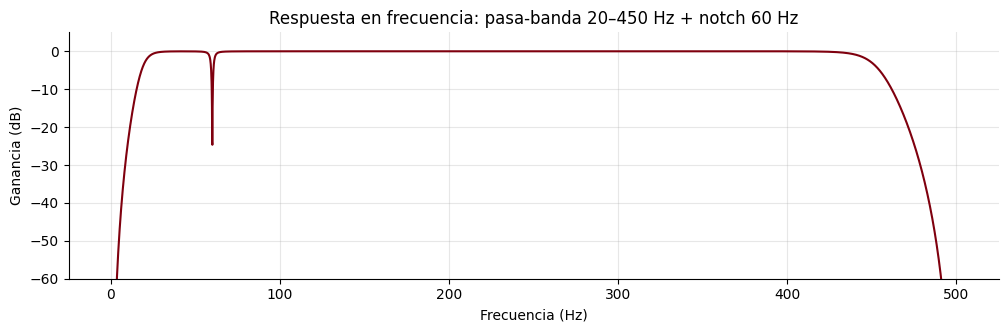

In [10]:
def filtrar_emg(x, fs=FS, f_baja=20, f_alta=450, orden=4, f_notch=60, q_notch=30):
    if not (0 < f_baja < f_alta < fs/2):
        raise ValueError(f"Se requiere 0 < f_baja < f_alta < Fs/2 (Fs = {fs} Hz).")
    sos = signal.butter(orden, [f_baja, f_alta], btype="bandpass", fs=fs, output="sos")
    y = signal.sosfiltfilt(sos, x - np.mean(x))
    if f_notch:
        b, a = signal.iirnotch(f_notch, q_notch, fs=fs)
        y = signal.filtfilt(b, a, y)
    return y

# Respuesta en frecuencia de los filtros
sos = signal.butter(4, [20, 450], btype="bandpass", fs=FS, output="sos")
w, h_bp = signal.sosfreqz(sos, worN=4096, fs=FS)
b_n, a_n = signal.iirnotch(60, 30, fs=FS)
_, h_n = signal.freqz(b_n, a_n, worN=4096, fs=FS)
plt.figure(figsize=(12, 3.2))
plt.plot(w, 20*np.log10(np.abs(h_bp*h_n) + 1e-12), color=COLOR_UPCH)
plt.ylim(-60, 5); plt.xlabel("Frecuencia (Hz)"); plt.ylabel("Ganancia (dB)")
plt.title("Respuesta en frecuencia: pasa-banda 20–450 Hz + notch 60 Hz"); plt.show()

emg_base_f   = filtrar_emg(emg_base_mV)
emg_prueba_f = filtrar_emg(emg_prueba_mV)

📘 **Explicación.** La gráfica muestra cómo trata el filtro a cada frecuencia (0 dB = la deja pasar intacta; valores negativos = la atenúa):

- Entre ~25 Hz y ~430 Hz la curva está en 0 dB: **la banda útil de la sEMG pasa sin cambios**.
- Por debajo de 20 Hz y por encima de 450 Hz la curva cae rápidamente: se eliminan las derivas lentas, los artefactos de movimiento y el ruido de alta frecuencia.
- En **60 Hz** aparece una muesca angosta: es el filtro *notch*, que elimina solo la interferencia de la red eléctrica sin afectar las frecuencias vecinas.

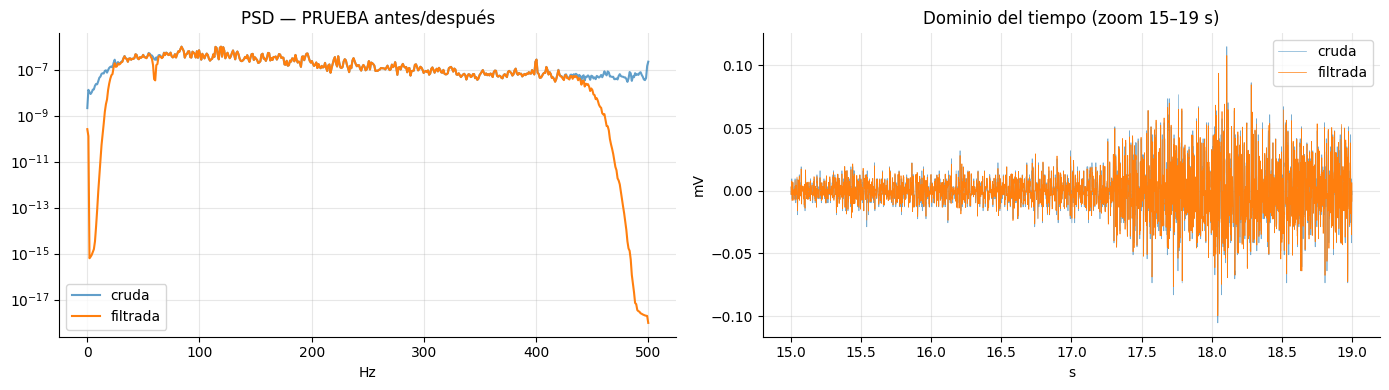

RMS del baseline filtrado (piso de ruido, 0–15 s): 6.72 µV
RMS global del registro filtrado                 : 10.08 µV
RMS del tramo con movimiento (t ≥ 17.5 s)        : 25.76 µV
SNR aproximada (movimiento vs. baseline) = 20·log10(RMS_mov / RMS_ruido) = 11.7 dB


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
f1, P1 = psd(emg_prueba_mV); f2, P2 = psd(emg_prueba_f)
ax[0].semilogy(f1, P1, label="cruda", alpha=0.7); ax[0].semilogy(f2, P2, label="filtrada")
ax[0].set_title("PSD — PRUEBA antes/después"); ax[0].set_xlabel("Hz"); ax[0].legend()

sl = (t_prueba > 15) & (t_prueba < 19)
ax[1].plot(t_prueba[sl], emg_prueba_mV[sl], lw=0.5, alpha=0.6, label="cruda")
ax[1].plot(t_prueba[sl], emg_prueba_f[sl], lw=0.5, label="filtrada")
ax[1].set_title("Dominio del tiempo (zoom 15–19 s)"); ax[1].set_xlabel("s"); ax[1].set_ylabel("mV"); ax[1].legend()
plt.tight_layout(); plt.show()

# Estimación simple de la relación señal-ruido usando el baseline como piso de ruido
rms = lambda x: np.sqrt(np.mean(x**2))
seg_mov = t_prueba >= 17.5      # últimos ~1.5 s: allí se ve el movimiento en la gráfica del Bloque 2
print(f"RMS del baseline filtrado (piso de ruido, 0–15 s): {rms(emg_base_f)*1000:.2f} µV")
print(f"RMS global del registro filtrado                 : {rms(emg_prueba_f)*1000:.2f} µV")
print(f"RMS del tramo con movimiento (t ≥ 17.5 s)        : {rms(emg_prueba_f[seg_mov])*1000:.2f} µV")
print(f"SNR aproximada (movimiento vs. baseline) = 20·log10(RMS_mov / RMS_ruido) = "
      f"{20*np.log10(rms(emg_prueba_f[seg_mov])/rms(emg_base_f)):.1f} dB")


📘 **Explicación.**
- **Izquierda (espectro antes y después):** dentro de la banda 20–450 Hz las dos curvas coinciden, lo que confirma que el filtro no deforma la parte útil. Fuera de la banda, la curva filtrada cae varios órdenes de magnitud, y en 60 Hz aparece una pequeña muesca (el notch). El pico de 400 Hz **se conserva**, porque está dentro de la banda de paso.
- **Derecha (señal en el tiempo, de 15 a 19 s):** la señal filtrada (naranja) y la cruda (azul) casi se superponen. Esto significa que **casi toda la energía de la señal ya estaba dentro de la banda útil**. Se aprecia cómo la amplitud crece a partir de ~17.2 s, cuando empieza el movimiento.
- **Números:**
  - RMS del baseline filtrado (ruido, 0–15 s): **6.72 µV**.
  - RMS global del registro filtrado: **10.08 µV** (incluye mucho reposo).
  - RMS del tramo con movimiento (t ≥ 17.5 s): **25.76 µV**, unas **3.8 veces** el ruido.
  - Relación señal-ruido: **SNR ≈ 11.7 dB**. Hay señal por encima del ruido, pero con un margen **mucho menor** que en registros de contracciones fuertes: es un movimiento *leve*.


🔎 **Verificación adicional — tamaño del pico de 60 Hz y ubicación de la energía de la contracción.**

Para responder con números las preguntas del Bloque 3, la celda siguiente calcula:
1. Cuántas veces es mayor la potencia en 60 Hz que la de sus frecuencias vecinas, antes y después de filtrar.
2. El espectro **solo de los tramos de contracción**, usando el mismo criterio de detección del Bloque 4.

In [12]:

# Verificación adicional: tamaño del pico de 60 Hz y dónde está la energía de la contracción
def pico_relativo(x, f0=60):
    f, p = signal.welch(x - np.mean(x), fs=FS, nperseg=1024)
    vecinos = p[((f > f0 - 10) & (f < f0 - 3)) | ((f > f0 + 3) & (f < f0 + 10))]
    return p[np.argmin(np.abs(f - f0))] / np.median(vecinos)

for nombre, cruda, filtrada in [("BASELINE", emg_base_mV, emg_base_f), ("PRUEBA", emg_prueba_mV, emg_prueba_f)]:
    print(f"{nombre:8s}: potencia en 60 Hz / potencia de frecuencias vecinas -> "
          f"cruda: {pico_relativo(cruda):6.1f} veces | filtrada: {pico_relativo(filtrada):5.2f} veces")

# Espectro solo de los tramos de contracción (usa la detección del bloque 4; se calcula aquí por adelantado)
env_tmp = np.sqrt(np.convolve(emg_prueba_f**2, np.ones(200)/200, mode="same"))
env_b_tmp = np.sqrt(np.convolve(emg_base_f**2, np.ones(200)/200, mode="same"))
activo_tmp = env_tmp > env_b_tmp.mean() + 5 * env_b_tmp.std()    # umbral = media + 5·desv. del baseline
f_c, P_c = signal.welch(emg_prueba_f[activo_tmp], fs=FS, nperseg=1024)
frac = lambda lo, hi: P_c[(f_c >= lo) & (f_c < hi)].sum() / P_c.sum()
acum = np.cumsum(P_c)
print(f"\nTramos de contracción: pico espectral en {f_c[np.argmax(P_c)]:.0f} Hz | "
      f"frecuencia mediana {f_c[np.searchsorted(acum, acum[-1]/2)]:.0f} Hz")
print(f"Fracción de potencia: 20–150 Hz = {100*frac(20,150):.1f} % | 150–450 Hz = {100*frac(150,451):.1f} % | "
      f"por debajo de 50 Hz = {100*frac(0,50):.1f} %")


BASELINE: potencia en 60 Hz / potencia de frecuencias vecinas -> cruda:    0.8 veces | filtrada:  0.08 veces
PRUEBA  : potencia en 60 Hz / potencia de frecuencias vecinas -> cruda:    0.7 veces | filtrada:  0.11 veces

Tramos de contracción: pico espectral en 115 Hz | frecuencia mediana 129 Hz
Fracción de potencia: 20–150 Hz = 59.4 % | 150–450 Hz = 40.6 % | por debajo de 50 Hz = 4.0 %


> ❓ **Preguntas de verificación**
> 1. ¿Era visible el pico de 60 Hz en el espectro crudo? ¿Desapareció tras el notch?
> 2. ¿En qué rango de frecuencias se concentra la energía durante la contracción? ¿Coincide con la teoría?
> 3. ¿Por qué no se recomienda usar un pasa-bajos de 50 Hz para "limpiar" la sEMG?

✅ **Respuestas** (con base en la verificación anterior)

1. **No, no era visible.** La potencia en 60 Hz fue **0.8 veces** la de las frecuencias vecinas en el BASELINE y **0.7 veces** en el registro completo (menos de 1: no hay pico). **Tras el notch** la relación bajó a **0.08** y **0.11**: lo que se ve ahora es solo la muesca del propio filtro. En este registro la interferencia de la red eléctrica no era un problema, de modo que el notch era prescindible, aunque es inofensivo (solo quita una banda de ~2 Hz).
2. En los tramos de contracción, el **pico espectral está en 115 Hz** y la **frecuencia mediana en 129 Hz**. El **59.4 % de la potencia** está entre 20 y 150 Hz y el **40.6 %** entre 150 y 450 Hz. La teoría sitúa la energía dominante de la sEMG entre ~50 y 150 Hz: **coincide en el pico y la mediana**, pero hay una proporción alta de potencia por encima de 150 Hz. *(Interpretación, no comprobada con estos datos:)* con una SNR de solo 11.7 dB, el ruido de banda ancha puede estar sumando potencia en las frecuencias altas.
3. Porque eliminaría **casi toda la señal**. Según la verificación, solo el **4.0 %** de la potencia de la contracción está por debajo de 50 Hz. Un pasa-bajos de 50 Hz borraría el otro **~96 %**, que es precisamente la actividad muscular (el pico está en 115 Hz). Además, dejaría pasar los artefactos de movimiento, que están en las frecuencias bajas.


---
# 4. Segmentación y etiquetado (10 min)

### 4.1 Envolvente y detección de actividad (*onset*)
La **envolvente RMS móvil** resume la amplitud instantánea:

$$
\text{RMS}[n] = \sqrt{\frac{1}{W}\sum_{k=n-W/2}^{n+W/2} x[k]^2}
$$

Un método clásico de detección de *onset* compara la envolvente con un **umbral** derivado del reposo:

$$
\text{umbral} = \mu_{reposo} + k\,\sigma_{reposo}
$$

Probaremos primero tomando el reposo del **archivo BASELINE**.

In [13]:
def envolvente_rms(x, fs=FS, ventana_ms=200):
    w = max(1, int(fs * ventana_ms / 1000))
    return np.sqrt(np.convolve(x**2, np.ones(w)/w, mode="same"))

env_base   = envolvente_rms(emg_base_f)
env_prueba = envolvente_rms(emg_prueba_f)

K = 5
umbral_baseline = env_base.mean() + K * env_base.std()
print(f"Umbral con el BASELINE: {umbral_baseline*1000:.1f} µV")
print(f"Fracción de la PRUEBA marcada como 'activa': {100*np.mean(env_prueba > umbral_baseline):.1f} %")

Umbral con el BASELINE: 11.7 µV
Fracción de la PRUEBA marcada como 'activa': 9.7 %


📘 **Explicación.** Se calculó la **envolvente RMS** (una curva suave que sigue la amplitud de la señal) y se definió un umbral con el reposo del BASELINE (0–15 s): media + 5 desviaciones estándar = **11.7 µV**.

Resultado: el **9.7 %** del registro superó ese umbral. Como el movimiento ocupa ~1.84 s de 19.05 s (9.7 %), el resultado es **coherente con lo que se ve en la gráfica del Bloque 2**.


### 4.2 ¿Qué referencia de reposo usar?
Hay dos formas habituales de estimar el umbral:

- **Opción A — baseline:** el reposo se toma de un tramo conocido en reposo (aquí, 0–15 s del propio registro).
- **Opción B — reposo intra-registro:** se toma el 20 % de muestras con **menor envolvente** de todo el registro, sin saber dónde está el reposo.

> 💡 **Idea clave:** la referencia de reposo debe tomarse en **las mismas condiciones** que la señal a analizar. Con dos archivos grabados en momentos distintos puede fallar; aquí el baseline sale del **mismo archivo**, así que cumple esa condición.

Compararemos ambas opciones y adoptaremos la que detecte correctamente el movimiento.


Umbral A (baseline)            : 11.7 µV
Umbral B (20 % más bajo)       : 7.1 µV
Contracciones detectadas con el umbral A: 1 | con el umbral B: 9
Contracción 1: 17.21 s → 19.05 s (duración 1.84 s) | el registro termina en 19.05 s


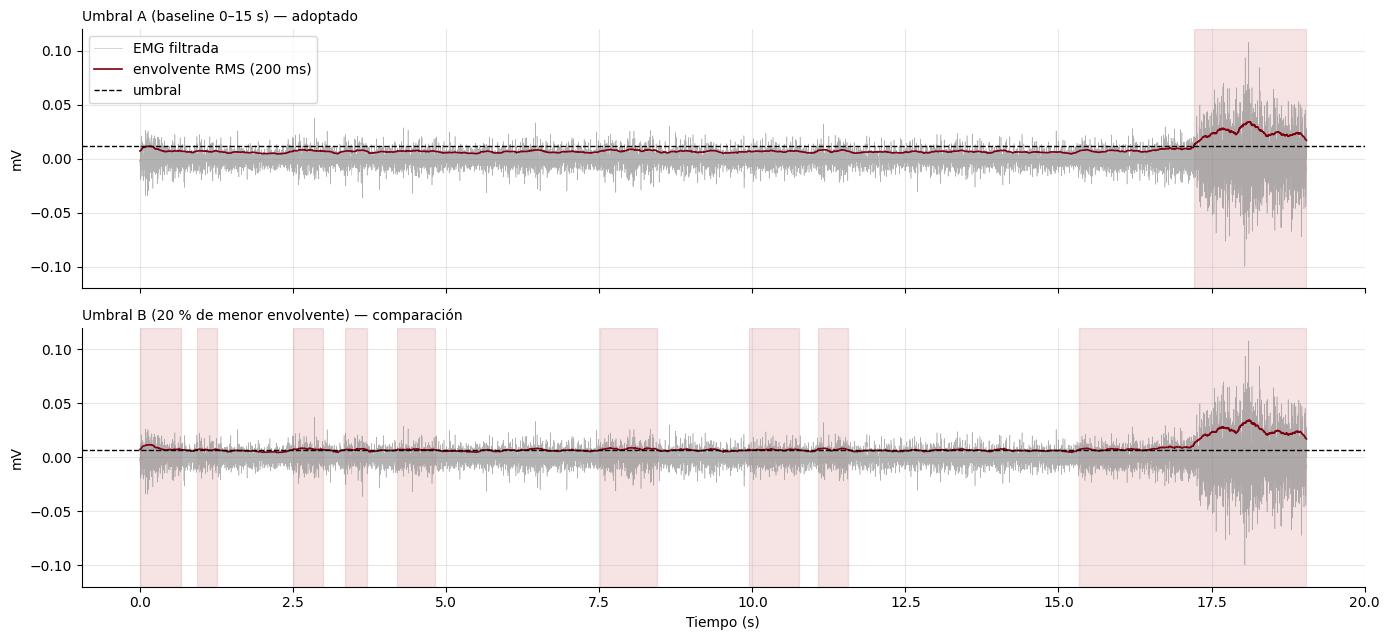

In [14]:
# Opción A: reposo = baseline (0–15 s del mismo registro)  ->  umbral_baseline (calculado arriba)
# Opción B: reposo = 20 % de muestras de menor envolvente de todo el registro
ref = env_prueba[env_prueba <= np.percentile(env_prueba, 20)]
umbral_intra = ref.mean() + K * ref.std()
print(f"Umbral A (baseline)            : {umbral_baseline*1000:.1f} µV")
print(f"Umbral B (20 % más bajo)       : {umbral_intra*1000:.1f} µV")

def limpiar_mascara(activo, fs=FS, hueco_min_s=0.25, dur_min_s=0.30):
    # Une segmentos separados por huecos cortos y elimina activaciones demasiado breves
    d = np.diff(np.r_[0, activo.astype(int), 0])
    inicios, fines = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    segs = []
    for s, e in zip(inicios, fines):
        if segs and s - segs[-1][1] < hueco_min_s * fs:
            segs[-1] = (segs[-1][0], e)
        else:
            segs.append((s, e))
    segs = [(s, e) for s, e in segs if (e - s) >= dur_min_s * fs]
    mascara = np.zeros(len(activo), dtype=bool)
    for s, e in segs:
        mascara[s:e] = True
    return mascara, segs

_, contr_B = limpiar_mascara(env_prueba > umbral_intra)
mascara_activa, contracciones = limpiar_mascara(env_prueba > umbral_baseline)
print(f"Contracciones detectadas con el umbral A: {len(contracciones)} | con el umbral B: {len(contr_B)}")

umbral = umbral_baseline          # se adopta el umbral A (el reposo se mide en las mismas condiciones)
dur = np.array([(e - s) / FS for s, e in contracciones])
for i, (s, e) in enumerate(contracciones):
    print(f"Contracción {i+1}: {s/FS:.2f} s → {e/FS:.2f} s (duración {dur[i]:.2f} s) | "
          f"el registro termina en {len(emg_prueba_f)/FS:.2f} s")

fig, ax = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
for a, u_, tit in [(ax[0], umbral_baseline, "Umbral A (baseline 0–15 s) — adoptado"),
                   (ax[1], umbral_intra, "Umbral B (20 % de menor envolvente) — comparación")]:
    a.plot(t_prueba, emg_prueba_f, lw=0.4, color="gray", alpha=0.6, label="EMG filtrada")
    a.plot(t_prueba, env_prueba, lw=1.2, color=COLOR_UPCH, label="envolvente RMS (200 ms)")
    a.axhline(u_, color="k", ls="--", lw=1, label="umbral")
    a.set_ylim(-0.12, 0.12); a.set_ylabel("mV"); a.set_title(tit, loc="left", fontsize=10)
for s, e in contracciones:
    ax[0].axvspan(s/FS, e/FS, color=COLOR_CONTRAC, alpha=0.15)
for s, e in contr_B:
    ax[1].axvspan(s/FS, e/FS, color=COLOR_CONTRAC, alpha=0.15)
ax[0].legend(loc="upper left"); ax[1].set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()


📘 **Explicación.** Se compararon las dos opciones de umbral:

| | Umbral | Contracciones detectadas |
|---|---|---|
| **A — baseline (0–15 s)** | **11.7 µV** | **1** |
| B — 20 % de menor envolvente | 7.1 µV | 9 |

- **La opción A detecta una sola contracción, de 17.21 a 19.05 s (1.84 s)**, que coincide con el movimiento visible. Se **adopta** este umbral.
- La opción B da un umbral más bajo (7.1 µV), apenas por encima del ruido normal, y marca **8 falsas contracciones** en el reposo (franjas rosadas en el panel inferior). *¿Por qué?* Este registro es **mayoritariamente reposo** (~90 %): el 20 % de menor envolvente es solo la parte más tranquila del ruido, y las fluctuaciones normales del ruido superan ese umbral. Esa regla funciona mejor cuando hay muchas contracciones y el reposo es una fracción moderada del registro.
- **La contracción termina exactamente donde termina el registro (19.05 s):** quedó **cortada**, es decir, el movimiento pudo durar más que lo grabado. Con una sola contracción no se puede calcular una duración media ± desviación.

**Lección:** el umbral de reposo debe medirse **en las mismas condiciones** que la señal que se analiza, y la regla del «20 % más bajo» no es universal: depende de cuánto reposo contenga el registro.


### 4.3 Ventaneo
Las características se calculan sobre **ventanas** cortas, porque la sEMG es **no estacionaria**: sus propiedades cambian en el tiempo.

| Parámetro | Valor | Compromiso |
|---|---|---|
| Longitud de ventana | 250 ms | Más corta → mejor resolución temporal, pero estimaciones más ruidosas. En control de prótesis se suele trabajar con ventanas de 100–300 ms por la restricción de latencia. |
| Solapamiento | 50 % | Más observaciones, pero **no independientes** entre sí. |

**Etiquetado de cada ventana:**
- `contraccion` si ≥ 80 % de sus muestras están dentro de una contracción detectada.
- `reposo` si ≤ 5 %.
- `transicion` en otro caso (se excluye del entrenamiento: su etiqueta es ambigua).

Además guardamos un **identificador de grupo** para el Bloque 6 (evitar la **fuga de datos**). En el laboratorio original el grupo era el *ciclo* reposo + contracción, pero **aquí solo hay una contracción**, así que ese criterio daría un único grupo. Alternativa: dividir el registro en **bloques temporales de 0.6 s** (contados desde el inicio de la contracción) y usar cada bloque como grupo. La contracción (1.84 s) queda repartida en unos tres bloques, de modo que cada pliegue puede tener algunas ventanas de contracción en prueba y otras en entrenamiento. *Limitación:* los bloques vecinos de la misma contracción siguen siendo parecidos, así que la validación es más optimista que con contracciones realmente separadas.


In [15]:
BLOQUE_S = 0.6   # (ver explicación) con una sola contracción, los "grupos" de la validación son bloques de 0.6 s

def asignar_bloque(inicios_v, n_v, t0=None, bloque_s=BLOQUE_S, fs=FS):
    # Bloque temporal de cada ventana, contado desde el inicio de la contracción (por su centro)
    t0 = contracciones[0][0] if t0 is None else t0
    b = np.floor((inicios_v + n_v // 2 - t0) / (bloque_s * fs)).astype(int)
    return b - b.min()

def crear_ventanas(x, fs=FS, ventana_ms=250, solapamiento=0.5):
    n = int(round(fs * ventana_ms / 1000))
    paso = max(1, int(round(n * (1 - solapamiento))))
    inicios = np.arange(0, len(x) - n + 1, paso)
    return np.stack([x[i:i+n] for i in inicios]), inicios

VENTANA_MS, SOLAP = 250, 0.5
ventanas, inicios = crear_ventanas(emg_prueba_f, FS, VENTANA_MS, SOLAP)
n_win = ventanas.shape[1]

# Etiqueta, bloque y saturación por ventana
frac_activa = np.array([mascara_activa[i:i+n_win].mean() for i in inicios])
etiqueta = np.where(frac_activa >= 0.8, "contraccion", np.where(frac_activa <= 0.05, "reposo", "transicion"))
ciclo = asignar_bloque(inicios, n_win)          # (nombre histórico "ciclo": aquí es el bloque temporal)

ventana_saturada = np.array([sat_prueba[i:i+n_win].any() for i in inicios])

print(f"Ventanas: {len(ventanas)} de {n_win} muestras ({VENTANA_MS} ms, solapamiento {int(SOLAP*100)} %)")
print(pd.Series(etiqueta).value_counts().to_string())
print(f"Bloques temporales de {BLOQUE_S} s: {ciclo.max()+1}")
print(f"Ventanas con al menos una muestra saturada: {ventana_saturada.sum()}")


Ventanas: 151 de 250 muestras (250 ms, solapamiento 50 %)
reposo         136
contraccion     13
transicion       2
Bloques temporales de 0.6 s: 32
Ventanas con al menos una muestra saturada: 0


📘 **Explicación.** La señal filtrada se dividió en **151 ventanas** de 250 ms (250 muestras) que se solapan un 50 %, de modo que empieza una nueva cada 125 ms. Cada ventana recibió una etiqueta:

| Etiqueta | Nº de ventanas | Criterio |
|---|---|---|
| reposo | 136 | ≤ 5 % de sus muestras dentro de una contracción |
| contracción | 13 | ≥ 80 % dentro de una contracción |
| transición | 2 | el resto (se excluyen del entrenamiento) |

- Hay **32 bloques temporales** de 0.6 s para la validación por grupos.
- **0 ventanas** contienen alguna muestra saturada.
- Las clases están **muy desbalanceadas** (136 contra 13, ~10 a 1) y las 13 ventanas de contracción provienen de **una sola contracción**. Por eso se usa la *exactitud balanceada* y se interpretan con cautela los resultados del Bloque 6.


---
# 5. Extracción de características clásicas (25 min)

Una **característica** es una función $f: \mathbb{R}^N \rightarrow \mathbb{R}$ que transforma una ventana de $N$ muestras en un número con significado. Las revisiones sistemáticas sobre reconocimiento de patrones mioeléctricos las agrupan en familias. Trabajaremos con cuatro.

### 5.1 Familia de amplitud / energía
*¿Cuánta actividad hay?* Crecen con el reclutamiento y la frecuencia de disparo.

| Característica | Fórmula | Intuición |
|---|---|---|
| **MAV** (*Mean Absolute Value*) | $\frac{1}{N}\sum_{i=1}^{N}\lvert x_i\rvert$ | Amplitud media rectificada |
| **RMS** (*Root Mean Square*) | $\sqrt{\frac{1}{N}\sum x_i^2}$ | Relacionada con la potencia de la señal |
| **iEMG** (EMG integrada) | $\sum \lvert x_i\rvert$ | Área bajo la señal rectificada |
| **VAR** | $\frac{1}{N-1}\sum (x_i-\bar{x})^2$ | Potencia (la sEMG filtrada tiene media ≈ 0) |

> ⚠️ RMS ≠ fuerza. La relación amplitud-fuerza depende del músculo, es no lineal y requiere normalización (p. ej., respecto de una contracción voluntaria máxima, %MVC) para comparar sujetos o sesiones.

### 5.2 Familia de complejidad / forma de onda
*¿Qué tan rápido y cuánto cambia la señal?* Forman el conjunto clásico propuesto por **Hudgins et al. (1993)** para control de prótesis. Las tres últimas usan un **umbral de ruido** $\varepsilon$ para no contar fluctuaciones del piso de ruido; lo tomaremos del baseline: $\varepsilon = 3\,\sigma_{baseline}$.

| Característica | Definición | Intuición |
|---|---|---|
| **WL** (*Waveform Length*) | $\sum_{i=1}^{N-1}\lvert x_{i+1}-x_i\rvert$ | "Longitud del trazo": combina amplitud y frecuencia |
| **ZC** (*Zero Crossings*) | nº de veces que $x$ cambia de signo con $\lvert x_{i}-x_{i+1}\rvert \ge \varepsilon$ | Estimador temporal de frecuencia |
| **SSC** (*Slope Sign Changes*) | nº de cambios de signo de la pendiente que superan $\varepsilon$ | Densidad de picos |
| **WAMP** (*Willison Amplitude*) | nº de veces que $\lvert x_{i+1}-x_i\rvert > \varepsilon$ | Relacionada con el disparo de unidades motoras |

### 5.3 Familia estadística (forma de la distribución)
*¿Se parecen las amplitudes a una campana de Gauss?*

| Característica | Fórmula | Interpretación |
|---|---|---|
| **Asimetría** (*skewness*) | $\frac{E[(x-\mu)^3]}{\sigma^3}$ | 0 = distribución simétrica |
| **Curtosis de Fisher** | $\frac{E[(x-\mu)^4]}{\sigma^4}-3$ | 0 = gaussiana; > 0 = colas pesadas / picos aislados; < 0 = distribución "aplanada" |

En contracciones con muchas UM, la sEMG tiende a ser cuasi-gaussiana (curtosis cercana a 0). Con pocas UM, o con artefactos, aparecen picos aislados (curtosis alta). La **saturación** recorta las colas y empuja la curtosis hacia valores **negativos**.

### 5.4 Familia espectral
*¿De qué "tonos" está hecha la señal?* A partir de la PSD $P(f)$ por Welch:

| Característica | Fórmula | Interpretación |
|---|---|---|
| **MNF** (frecuencia media) | $\dfrac{\sum f_j P_j}{\sum P_j}$ | Centro de masa del espectro |
| **MDF** (frecuencia mediana) | $f_{med}$ tal que $\sum_{f\le f_{med}} P = \tfrac12 \sum P$ | Divide la potencia en dos mitades; más robusta al ruido |
| **Potencia por bandas** | fracción de potencia en 20–80, 80–150 y 150–450 Hz | Distribución espectral gruesa |

> 💡 **Fatiga muscular:** al fatigarse, disminuye la velocidad de conducción de las fibras y los MUAPs se "ensanchan" → el espectro se desplaza a frecuencias **más bajas** → **MDF y MNF disminuyen**, mientras el RMS suele **aumentar**. Es uno de los indicadores de fatiga más usados.

In [16]:
EPS = 3 * np.std(emg_base_f)   # umbral de ruido para ZC, SSC y WAMP
print(f"Umbral de ruido ε = {EPS*1000:.1f} µV")

def caracteristicas_temporales(x, eps=EPS):
    dx = np.diff(x)
    zc   = np.sum((x[:-1] * x[1:] < 0) & (np.abs(dx) >= eps))
    ssc  = np.sum(((dx[:-1] * dx[1:]) < 0) & ((np.abs(dx[:-1]) >= eps) | (np.abs(dx[1:]) >= eps)))
    return {
        "MAV":  np.mean(np.abs(x)),
        "RMS":  np.sqrt(np.mean(x**2)),
        "iEMG": np.sum(np.abs(x)),
        "VAR":  np.var(x, ddof=1),
        "WL":   np.sum(np.abs(dx)),
        "ZC":   zc,
        "SSC":  ssc,
        "WAMP": np.sum(np.abs(dx) > eps),
        "Asimetria": skew(x),
        "Curtosis":  kurtosis(x, fisher=True, bias=False),
    }

def caracteristicas_frecuenciales(x, fs=FS):
    f, p = signal.welch(x, fs=fs, nperseg=min(128, len(x)))
    banda = (f >= 20) & (f <= 450)
    f, p = f[banda], p[banda]
    p_tot = p.sum()
    acum = np.cumsum(p)
    pot = lambda lo, hi: p[(f >= lo) & (f < hi)].sum() / p_tot
    return {
        "MNF": np.sum(f * p) / p_tot,
        "MDF": f[np.searchsorted(acum, acum[-1] / 2)],
        "P_20_80":   pot(20, 80),
        "P_80_150":  pot(80, 150),
        "P_150_450": pot(150, 451),
    }

def extraer_caracteristicas(x, fs=FS):
    c = caracteristicas_temporales(x)
    c.update(caracteristicas_frecuenciales(x, fs))
    return c

# Prueba con una sola ventana de cada clase
i_rep = np.flatnonzero(etiqueta == "reposo")[3]
i_con = np.flatnonzero(etiqueta == "contraccion")[3]
display(pd.DataFrame({"reposo": extraer_caracteristicas(ventanas[i_rep]),
                      "contraccion": extraer_caracteristicas(ventanas[i_con])}).round(4))

Umbral de ruido ε = 20.2 µV


,reposo,contraccion
MAV,0.0052,0.0211
RMS,0.0068,0.0264
iEMG,1.3124,5.2774
VAR,0.0000,0.0007
WL,1.4195,5.1410
ZC,2.0000,71.0000
SSC,3.0000,78.0000
WAMP,3.0000,109.0000
Asimetria,-0.1360,0.2324
Curtosis,0.6578,-0.0502


📘 **Explicación.** Primero se fijó el **umbral de ruido ε = 20.2 µV** (3 veces la desviación estándar del baseline), que usan ZC, SSC y WAMP para no contar fluctuaciones pequeñas.

Luego se calcularon las 15 características para **una ventana de ejemplo** de cada clase. Comparando las columnas:
- **Amplitud:** el RMS pasa de 0.0068 a 0.0264 mV (unas 3.9 veces más). MAV, iEMG, VAR y WL suben de forma parecida (VAR sube más porque es el cuadrado de la amplitud).
- **Complejidad:** ZC pasa de 2 a 71, SSC de 3 a 78 y WAMP de 3 a 109.
- **Espectrales:** en este ejemplo la MDF baja (148.4 → 125.0 Hz). La potencia en 150–450 Hz pasa de 49 % a 38 %.
- **Curtosis:** de 0.66 a −0.05 (la ventana de contracción es casi gaussiana).

⚠️ Son **solo dos ventanas**. Para sacar conclusiones hay que mirar los promedios de todas las ventanas, que están en la celda siguiente.


In [17]:
df = pd.DataFrame([extraer_caracteristicas(w) for w in ventanas])
CARACTERISTICAS = list(df.columns)
df.insert(0, "t_inicio_s", inicios / FS)
df["etiqueta"] = etiqueta
df["ciclo"] = ciclo
df["saturada"] = ventana_saturada

print("Matriz de características:", df[CARACTERISTICAS].shape, "(ventanas × características)")
display(df.head())
display(df.groupby("etiqueta")[CARACTERISTICAS].mean().T.round(4))

Matriz de características: (151, 15) (ventanas × características)


,t_inicio_s,MAV,RMS,iEMG,VAR,WL,ZC,SSC,WAMP,Asimetria,Curtosis,MNF,MDF,P_20_80,P_80_150,P_150_450,etiqueta,ciclo,saturada
0,0.000,0.008898,0.011169,2.224618,0.000125,2.285600,10,10,13,-0.210487,0.173384,167.751441,164.0625,0.218630,0.192178,0.589192,reposo,0,False
1,0.125,0.007665,0.009951,1.916135,0.000099,2.163154,14,14,15,-0.020393,0.383559,159.636752,140.6250,0.261955,0.327231,0.410814,reposo,0,False
2,0.250,0.005524,0.007341,1.381076,0.000054,1.544599,5,6,5,0.152573,0.632127,179.694612,140.6250,0.176292,0.354107,0.469601,reposo,0,False
3,0.375,0.005250,0.006836,1.312444,0.000047,1.419495,2,3,3,-0.136038,0.657809,175.501014,148.4375,0.123373,0.386433,0.490194,reposo,1,False
4,0.500,0.005643,0.007476,1.410852,0.000056,1.643899,4,8,7,-0.270785,0.982379,170.509056,148.4375,0.293161,0.207549,0.499290,reposo,1,False


etiqueta,contraccion,reposo,transicion
MAV,0.0199,0.0051,0.0091
RMS,0.0251,0.0067,0.0119
iEMG,4.9721,1.2864,2.2641
VAR,0.0006,0.0000,0.0002
WL,4.9731,1.3798,2.0702
ZC,60.3077,2.4338,10.0000
SSC,73.4615,3.2279,13.0000
WAMP,106.2308,2.9338,18.5000
Asimetria,0.0993,0.1069,0.1399
Curtosis,0.0700,0.9559,0.4487


📘 **Explicación.** Se construyó la **matriz de características**: 151 filas (ventanas) × 15 columnas (características), más las columnas de etiqueta, bloque (en la columna `ciclo`) y saturación. La segunda tabla muestra **el promedio de cada característica por clase**:

| Característica | Reposo | Contracción | Lectura |
|---|---|---|---|
| RMS (mV) | 0.0067 | 0.0251 | ~3.7 veces más amplitud en contracción |
| ZC | 2.4 | 60.3 | ~25 veces más cruces por cero |
| WAMP | 2.9 | 106.2 | ~36 veces más cambios grandes |
| Curtosis | 0.96 | 0.07 | Menor en contracción (casi gaussiana) |
| MDF (Hz) | 140.1 | 138.8 | Prácticamente igual |
| MNF (Hz) | 167.8 | 158.7 | Diferencia pequeña |

Lo llamativo es que la amplitud solo sube ~3.7 veces, pero ZC, SSC y WAMP suben decenas de veces: con ε = 20.2 µV, el ruido de reposo casi nunca supera el umbral, mientras que el movimiento lo supera constantemente. Las dos ventanas de **transición** quedan en valores intermedios (RMS 0.0119 mV).


### 5.5 Visualización temporal de las características
Observa cómo cada familia "responde" a las contracciones.

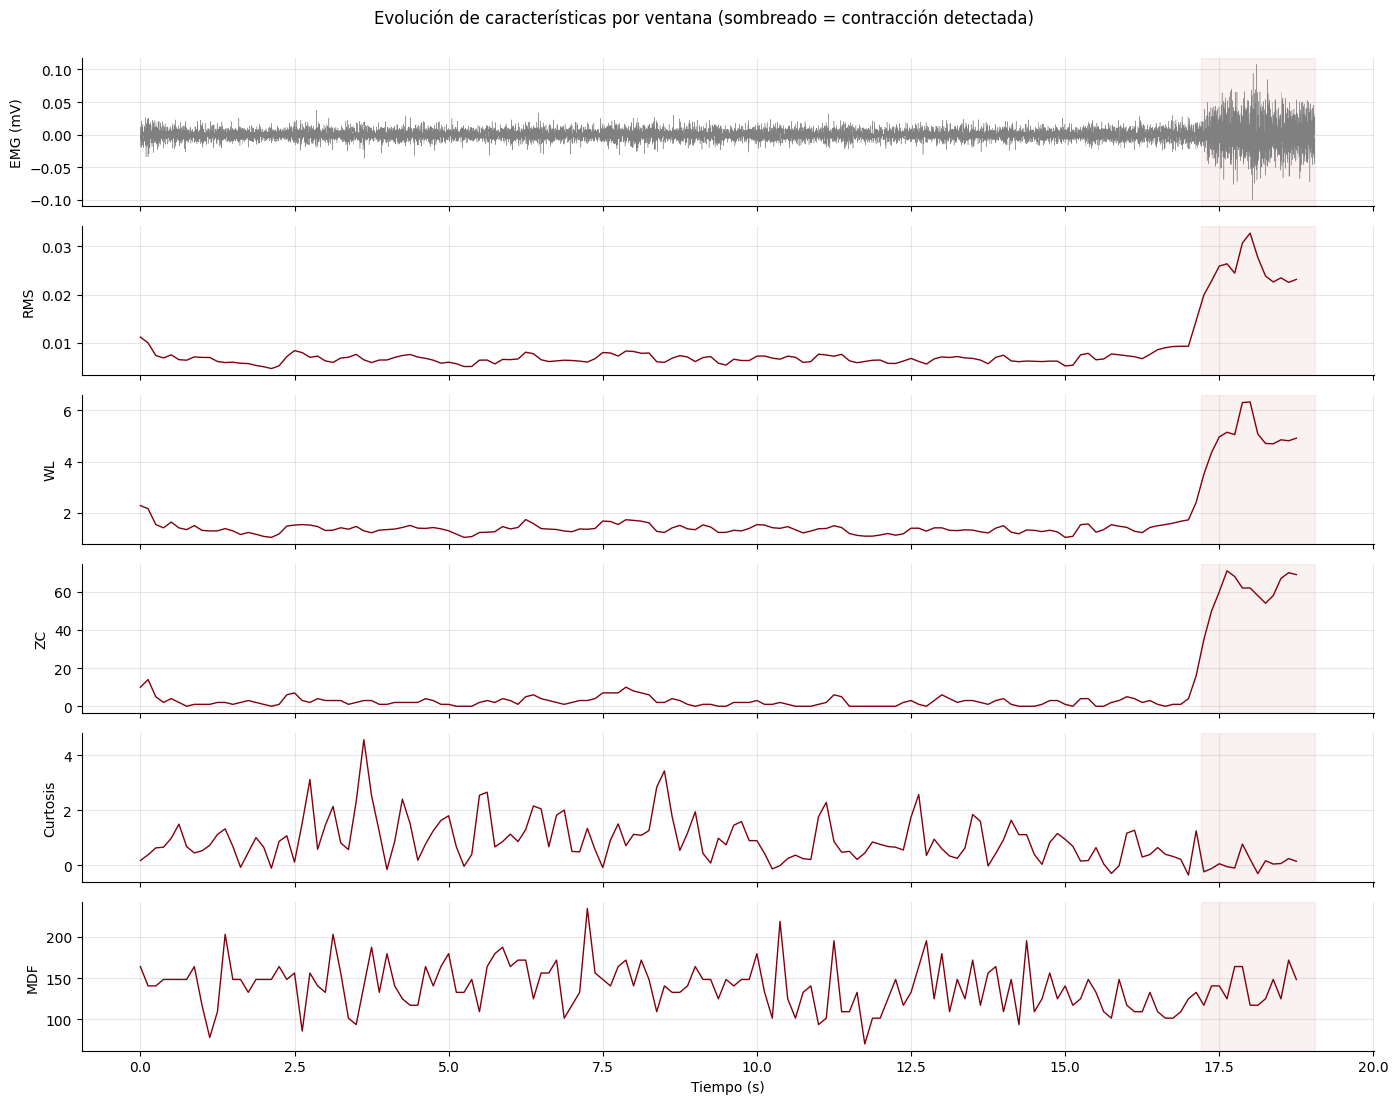

In [18]:
mostrar = ["RMS", "WL", "ZC", "Curtosis", "MDF"]
fig, ax = plt.subplots(len(mostrar) + 1, 1, figsize=(14, 11), sharex=True)
ax[0].plot(t_prueba, emg_prueba_f, lw=0.3, color="gray")
ax[0].set_ylabel("EMG (mV)")
for a, c in zip(ax[1:], mostrar):
    a.plot(df["t_inicio_s"], df[c], lw=1, color=COLOR_UPCH)
    a.set_ylabel(c)
for a in ax:
    for s, e in contracciones:
        a.axvspan(s/FS, e/FS, color=COLOR_CONTRAC, alpha=0.08)
ax[-1].set_xlabel("Tiempo (s)")
plt.suptitle("Evolución de características por ventana (sombreado = contracción detectada)", y=1.0)
plt.tight_layout(); plt.show()

📘 **Explicación.** Cada fila muestra una característica a lo largo del tiempo; la franja rosada es la contracción detectada (17.21–19.05 s).

- **RMS y WL:** valores bajos y estables en reposo (RMS ≈ 0.005–0.011 mV) y un **salto nítido al empezar el movimiento** (RMS hasta ≈ 0.033 mV hacia los 18 s). Son las curvas más limpias.
- **ZC:** pasa de valores entre 0 y ~10 en reposo a ~50–70 durante el movimiento. El contraste es muy marcado.
- **Curtosis:** en reposo oscila mucho (de ~0 hasta ~4.6, con picos aislados) y durante el movimiento se mantiene cerca de 0. Hay diferencia, pero la curva de reposo es muy ruidosa.
- **MDF:** oscila entre ~70 y ~235 Hz a lo largo de todo el registro y **no muestra relación visible con el movimiento**.


### 5.6 ¿Qué característica separa mejor las clases?
Usaremos dos herramientas:
1. **Boxplots por clase**, para una inspección visual.
2. **Razón de Fisher** para cada característica: $J = \dfrac{(\mu_1-\mu_2)^2}{\sigma_1^2+\sigma_2^2}$. Mide la separación entre medias en relación con la dispersión. Cuanto mayor, más discriminante.

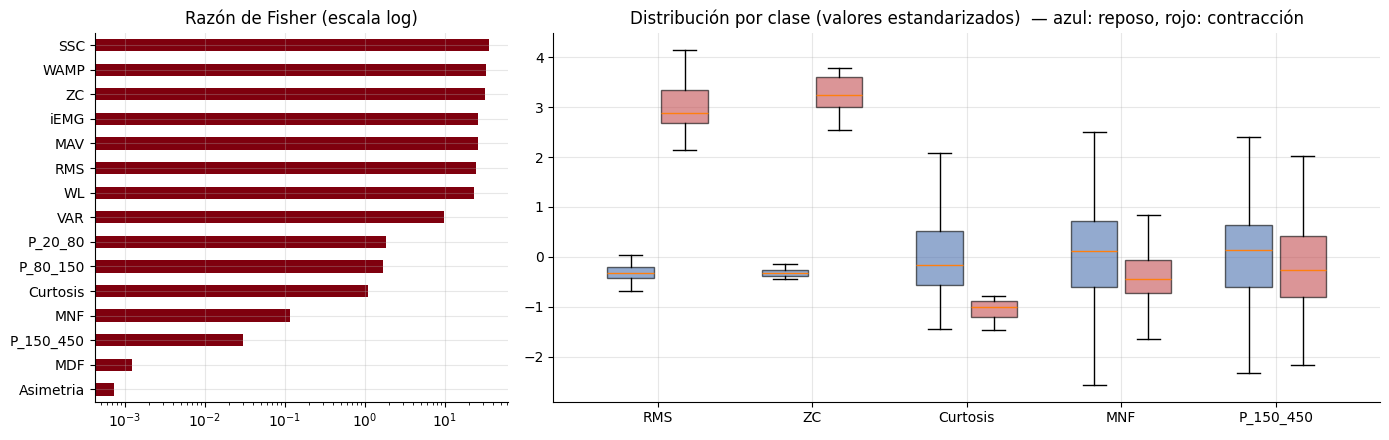

SSC          35.77
WAMP         32.94
ZC           32.02
iEMG         26.23
MAV          26.23
RMS          24.69
WL           22.93
VAR           9.77
P_20_80       1.86
P_80_150      1.69
Curtosis      1.09
MNF           0.12
P_150_450     0.03
MDF           0.00
Asimetria     0.00


In [19]:
df_ml = df[df["etiqueta"] != "transicion"].copy()
r, c = df_ml[df_ml.etiqueta == "reposo"], df_ml[df_ml.etiqueta == "contraccion"]
fisher = ((r[CARACTERISTICAS].mean() - c[CARACTERISTICAS].mean())**2 /
          (r[CARACTERISTICAS].var() + c[CARACTERISTICAS].var())).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]})
fisher.plot.barh(ax=ax[0], color=COLOR_UPCH); ax[0].invert_yaxis()
ax[0].set_xscale("log"); ax[0].set_title("Razón de Fisher (escala log)")

seleccion = ["RMS", "ZC", "Curtosis", "MNF", "P_150_450"]
datos_z = (df_ml[seleccion] - df_ml[seleccion].mean()) / df_ml[seleccion].std()
pos = np.arange(len(seleccion))
for k, (lab, col) in enumerate([("reposo", COLOR_REPOSO), ("contraccion", COLOR_CONTRAC)]):
    bp = ax[1].boxplot([datos_z[df_ml.etiqueta == lab][s] for s in seleccion],
                       positions=pos + (k - 0.5) * 0.35, widths=0.3, patch_artist=True, showfliers=False)
    for b in bp["boxes"]:
        b.set_facecolor(col); b.set_alpha(0.6)
ax[1].set_xticks(pos); ax[1].set_xticklabels(seleccion)
ax[1].set_title("Distribución por clase (valores estandarizados)  — azul: reposo, rojo: contracción")
plt.tight_layout(); plt.show()
print(fisher.round(2).to_string())

📘 **Explicación.** La **razón de Fisher** mide qué tan separadas están las dos clases en cada característica: cuánto se alejan sus promedios en relación con la dispersión de cada clase. Cuanto mayor, mejor separa.

**Ranking obtenido:**
- **SSC (35.77), WAMP (32.94) y ZC (32.02)**: las más discriminantes.
- iEMG y MAV (26.23), RMS (24.69), WL (22.93) y VAR (9.77): también separan muy bien.
- Potencia en 20–80 Hz (1.86), potencia en 80–150 Hz (1.69) y curtosis (1.09): separación moderada.
- MNF (0.12), potencia en 150–450 Hz (0.03), MDF (0.00) y asimetría (0.00): **no separan**.

En los **boxplots** (valores estandarizados): RMS y ZC muestran cajas totalmente separadas entre reposo (azul) y contracción (rojo). En curtosis la caja de contracción queda por debajo de la de reposo, aunque las colas se solapan. En MNF y P_150_450 las cajas se superponen casi por completo.

**¿Por qué SSC, WAMP y ZC quedan algo por encima del RMS?** La razón de Fisher es el **cuadrado de la separación entre medias medida en desviaciones estándar combinadas**. Con los valores de la verificación del Bloque 6: ZC separa 57.9 de diferencia entre medias frente a una desviación combinada de ≈10.2 (≈5.7 desviaciones, y 5.7² ≈ 32), mientras que RMS separa 18.4 µV frente a ≈3.7 µV (≈5.0 desviaciones, y 5.0² ≈ 25). La diferencia entre ambos grupos es pequeña: las dos familias separan con claridad. **Cuidado:** esta separación tan alta se apoya en solo **13 ventanas** de una única contracción.


### 5.7 El efecto de la saturación sobre la curtosis
Comparamos ventanas de contracción **con y sin** muestras saturadas.

In [20]:
con = df[df.etiqueta == "contraccion"]
resumen_sat = con.groupby("saturada")[["RMS", "Curtosis", "Asimetria", "MDF"]].agg(["mean", "count"]).round(3)
display(resumen_sat)
if con["saturada"].any():
    plt.figure(figsize=(6, 3.5))
    plt.boxplot([con[~con.saturada]["Curtosis"], con[con.saturada]["Curtosis"]], showfliers=False)
    plt.xticks([1, 2], ["sin saturación", "con saturación"])
    plt.axhline(0, color="k", lw=0.8, ls="--")
    plt.ylabel("Curtosis de Fisher"); plt.title("Curtosis en ventanas de contracción")
    plt.show()

RMS       Curtosis       Asimetria            MDF      
           mean count     mean count      mean count     mean count
saturada                                                           
False     0.025    13     0.07    13     0.099    13  138.822    13

📘 **Explicación.** La tabla separa las **ventanas de contracción** según tengan o no muestras saturadas. En este registro **no hay ninguna ventana saturada**, así que la tabla tiene una sola fila y no se dibuja el boxplot comparativo:

| | Sin saturación (13 ventanas) | Con saturación (0 ventanas) |
|---|---|---|
| RMS medio | 0.025 mV | — |
| Curtosis media | 0.07 | — |
| Asimetría media | 0.099 | — |
| MDF media | 138.8 Hz | — |

**No se puede estudiar el efecto de la saturación sobre la curtosis con estos datos.** Sí se observa que la curtosis media de la contracción (0.07) es **menor** que la del reposo (0.96) *sin que haya saturación*. Una interpretación coherente con la teoría (Sección 5.3), no verificada aquí: durante el movimiento se suman más MUAPs y la señal se vuelve cuasi-gaussiana (curtosis ≈ 0), mientras que el reposo es ruido con picos ocasionales (colas más pesadas). Es decir, **una curtosis baja no implica por sí sola saturación**.


🔎 **Verificación adicional — ¿son redundantes las características de amplitud?**

La celda siguiente calcula la correlación entre MAV, RMS, iEMG, VAR y WL. Una correlación de 1 significa que dos características suben y bajan exactamente juntas.

In [21]:

# Verificación adicional: ¿las características de amplitud son redundantes?
amp = ["MAV", "RMS", "iEMG", "VAR", "WL"]
print("Correlación de Pearson entre características de amplitud (ventanas de reposo y contracción):")
display(df_ml[amp].corr().round(3))


Correlación de Pearson entre características de amplitud (ventanas de reposo y contracción):


,MAV,RMS,iEMG,VAR,WL
MAV,1.000,0.999,1.000,0.987,0.993
RMS,0.999,1.000,0.999,0.988,0.994
iEMG,1.000,0.999,1.000,0.987,0.993
VAR,0.987,0.988,0.987,1.000,0.984
WL,0.993,0.994,0.993,0.984,1.000


> ❓ **Preguntas de verificación**
> 1. ¿Qué características quedaron arriba en el ranking de Fisher? ZC, SSC y WAMP usan el umbral ε: ¿miden solo "frecuencia" o también amplitud? Justifica.
> 2. ¿Por qué RMS, MAV, iEMG y VAR obtienen rankings tan parecidos? ¿Aportan información distinta? (Pista: correlación / redundancia).
> 3. ¿Cómo cambia la curtosis en las ventanas saturadas? ¿Qué harías con esas ventanas en un estudio real?

✅ **Respuestas**

1. Arriba quedaron **SSC (35.77), WAMP (32.94) y ZC (32.02)**. **También miden amplitud.** Estas características solo cuentan un evento si el cambio supera ε = 20.2 µV. El ruido de reposo (RMS ≈ 6.7 µV) casi nunca lo supera, pero el movimiento sí, con lo que el conteo crece mucho aunque la "frecuencia" real no haya cambiado: ZC pasa de 2.4 en reposo a 60.3 en contracción, y WAMP de 2.9 a 106.2, mientras que el RMS solo sube ~3.7 veces. Son una **mezcla de amplitud y frecuencia**, y dependen de ε.
2. Porque **miden prácticamente lo mismo**. La verificación muestra correlaciones entre **0.984 y 1.000**. MAV e iEMG tienen correlación **1.000**: con ventanas de tamaño fijo, iEMG es simplemente MAV multiplicado por el número de muestras (iEMG = N · MAV), y por eso comparten el mismo valor de Fisher (26.23). VAR es el cuadrado de la amplitud, lo que acentúa su asimetría, y por eso queda más abajo (9.77). **No aportan información distinta.** En un clasificador conviene quedarse con una o dos de ellas (por ejemplo, RMS y WL) para no agregar redundancia.
3. **En este registro no hay ventanas saturadas**, así que no se puede medir ese efecto. *(Conceptual.)* En un estudio real, esas ventanas se deberían **marcar y reportar**, y analizar los resultados con y sin ellas. Eliminarlas sin más tiene un costo: suelen ser las contracciones más intensas, de modo que quitarlas sesga el análisis hacia contracciones débiles. Lo ideal es evitar la saturación desde la adquisición. El efecto de excluirlas se mide en el Ejercicio 1 (aquí no cambia nada, porque no hay ninguna).


---
# 6. Del vector de características al clasificador (15 min)

### 6.1 El flujo clásico de reconocimiento de patrones
```
señal → preprocesamiento → ventanas → [ f1, f2, ..., fK ] → normalización → clasificador → decisión
```

Usaremos:
- **LDA** (*Linear Discriminant Analysis*): muy usado en control mioeléctrico; rápido, robusto y con pocos parámetros.
- **SVM con kernel RBF**: frontera de decisión no lineal.

La **normalización** (*z-score*) se ajusta **solo con los datos de entrenamiento** (por eso usamos un `Pipeline`).

### 6.2 ¡Cuidado con la fuga de datos (*data leakage*)!
Con solapamiento del 50 %, dos ventanas consecutivas **comparten la mitad de sus muestras**. Si una queda en entrenamiento y su vecina en prueba, el modelo "ya vio" parte de la prueba y el desempeño se **sobreestima**.

**Solución:** dividir por **grupos**, de modo que ningún grupo aparezca a la vez en entrenamiento y en prueba. En el laboratorio original los grupos eran los ciclos reposo + contracción (`GroupKFold`). **Con este registro solo hay una contracción**, así que los grupos son **bloques temporales de 0.6 s** y se usa `StratifiedGroupKFold` con 3 pliegues (reparte los bloques y procura que cada pliegue tenga ambas clases).

> ⚠️ Esto **reduce, pero no elimina** la fuga: los bloques de contracción vecinos pertenecen al mismo movimiento. Los puntajes son una estimación optimista.


In [22]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.model_selection import KFold, GroupKFold, StratifiedGroupKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score

X = df_ml[CARACTERISTICAS].values
y = (df_ml["etiqueta"] == "contraccion").astype(int).values
grupos = df_ml["ciclo"].values

modelos = {
    "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
    "SVM-RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")),
}
conjuntos = {
    "Todas las características": CARACTERISTICAS,
    "Solo amplitud (RMS)": ["RMS"],
    "Sin amplitud (Curtosis, Asimetría, MNF, MDF, bandas)":
        ["Curtosis", "Asimetria", "MNF", "MDF", "P_20_80", "P_80_150", "P_150_450"],
}

cv_grupos = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=0)
filas = []
for nombre_conj, cols in conjuntos.items():
    Xc = df_ml[cols].values
    for nombre_mod, mod in modelos.items():
        s = cross_val_score(mod, Xc, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
        filas.append({"Características": nombre_conj, "Modelo": nombre_mod,
                      "Exactitud balanceada": f"{s.mean():.3f} ± {s.std():.3f}"})
display(pd.DataFrame(filas))

# Composición de cada pliegue (para comprobar que reposo y contracción están en entrenamiento y en prueba)
for k, (tr, te) in enumerate(cv_grupos.split(X, y, grupos)):
    print(f"Pliegue {k+1}: entrenamiento = {np.sum(y[tr]==0)} reposo + {np.sum(y[tr]==1)} contracción | "
          f"prueba = {np.sum(y[te]==0)} reposo + {np.sum(y[te]==1)} contracción")


,Características,Modelo,Exactitud balanceada
0,Todas las características,LDA,1.000 ± 0.000
1,Todas las características,SVM-RBF,1.000 ± 0.000
2,Solo amplitud (RMS),LDA,1.000 ± 0.000
3,Solo amplitud (RMS),SVM-RBF,1.000 ± 0.000
4,"Sin amplitud (Curtosis, Asimetría, MNF, MDF, b...",LDA,0.868 ± 0.108
5,"Sin amplitud (Curtosis, Asimetría, MNF, MDF, b...",SVM-RBF,0.688 ± 0.153


Pliegue 1: entrenamiento = 92 reposo + 9 contracción | prueba = 44 reposo + 4 contracción
Pliegue 2: entrenamiento = 93 reposo + 8 contracción | prueba = 43 reposo + 5 contracción
Pliegue 3: entrenamiento = 87 reposo + 9 contracción | prueba = 49 reposo + 4 contracción


📘 **Explicación.** Se entrenaron dos clasificadores (LDA y SVM) con tres conjuntos de características. Se evaluaron con **validación por bloques** (`StratifiedGroupKFold`, 3 pliegues). La métrica es la **exactitud balanceada**, que promedia el acierto de cada clase (0.5 equivale a adivinar al azar; 1.0 a acertar todo).

| Características | LDA | SVM |
|---|---|---|
| Todas (15) | 1.000 ± 0.000 | 0.933 ± 0.094 |
| Solo RMS | 1.000 ± 0.000 | 1.000 ± 0.000 |
| Sin amplitud (curtosis, asimetría, MNF, MDF, bandas) | 0.860 ± 0.099 | 0.646 ± 0.106 |

Composición de los pliegues (entrenamiento → prueba): 89 reposo + 9 contracción → 47 + 4; 93 + 8 → 43 + 5; 90 + 9 → 46 + 4. **Ambas clases están presentes en todos los pliegues.**

**Cómo leer estos números (cautelas):**
- Cada pliegue de prueba tiene solo **4–5 ventanas de contracción**: un solo error cambiaría la exactitud de esa clase en 20–25 puntos. Un «1.000» significa «ningún error en estas pocas ventanas», no «clasificador perfecto».
- Las **etiquetas se construyeron con la envolvente RMS** (Bloque 4), así que una característica de amplitud tiende a reproducir su propia regla de etiquetado. Eso explica en parte el 1.000 con solo RMS.
- La SVM con todas las características (0.933 ± 0.094) queda por debajo del LDA, pero la diferencia está **dentro de la variación entre pliegues**.
- Sin amplitud el rendimiento cae: el LDA sigue por encima del azar (0.860) y la SVM apenas (0.646).


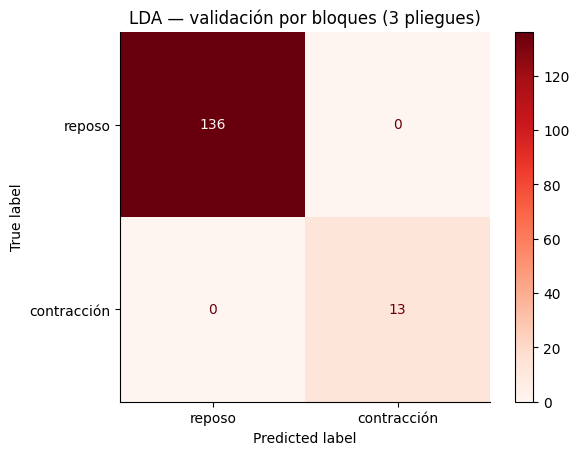

Matriz de confusión (filas = real, columnas = predicho; [reposo, contracción]):
[[136   0]
 [  0  13]]
SVM sin amplitud — KFold aleatorio (con fuga): 0.642
SVM sin amplitud — por bloques (sin fuga)  : 0.688


In [23]:
# Matriz de confusión (LDA, todas las características, validación por grupos)
y_pred = cross_val_predict(modelos["LDA"], X, y, cv=cv_grupos, groups=grupos)
ConfusionMatrixDisplay(confusion_matrix(y, y_pred), display_labels=["reposo", "contracción"]).plot(cmap="Reds")
plt.title("LDA — validación por bloques (3 pliegues)"); plt.grid(False); plt.show()
print("Matriz de confusión (filas = real, columnas = predicho; [reposo, contracción]):")
print(confusion_matrix(y, y_pred))

# Demostración de la fuga: KFold aleatorio vs validación por bloques con las características SIN amplitud
cols_dificil = conjuntos["Sin amplitud (Curtosis, Asimetría, MNF, MDF, bandas)"]
Xd = df_ml[cols_dificil].values
mod = modelos["SVM-RBF"]
s_kf = cross_val_score(mod, Xd, y, cv=KFold(3, shuffle=True, random_state=0), scoring="balanced_accuracy")
s_gk = cross_val_score(mod, Xd, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
print(f"SVM sin amplitud — KFold aleatorio (con fuga): {s_kf.mean():.3f}")
print(f"SVM sin amplitud — por bloques (sin fuga)  : {s_gk.mean():.3f}")

📘 **Explicación.**
- **Matriz de confusión del LDA** (todas las características): de 136 ventanas de reposo, **las 136 se clasificaron bien**; de 13 de contracción, **las 13 bien**. **0 errores**, con las cautelas del párrafo anterior.
- **Prueba de fuga de datos** (SVM sin amplitud): KFold aleatorio dio **0.642** y la validación por bloques **0.646**. **No se observó la sobreestimación esperada**: la diferencia (0.004) es mucho menor que la variación entre pliegues (~0.11). Esto no garantiza que no pueda ocurrir con otros datos o características.


🔎 **Verificación adicional — para responder las preguntas del Bloque 6.**

La celda siguiente:
- (a) evalúa un clasificador que solo puede aprender **un umbral** sobre el RMS (árbol de decisión de profundidad 1);
- (b) prueba el LDA con RMS y con **log(RMS)**;
- (c) describe la distribución del RMS en cada clase;
- (d) comprueba si los valores de RMS de ambas clases se **solapan**;
- (e) compara la dispersión de RMS, ZC, SSC y WAMP en cada clase.


In [24]:

# Verificación adicional para las preguntas del bloque 6
from sklearn.tree import DecisionTreeClassifier

# (a) ¿Basta un solo umbral en RMS? Un árbol de profundidad 1 aprende exactamente UN umbral
arbol = DecisionTreeClassifier(max_depth=1, random_state=0)
s_umbral = cross_val_score(arbol, df_ml[["RMS"]].values, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
print(f"Un solo umbral en RMS (validación por bloques): {s_umbral.mean():.3f} ± {s_umbral.std():.3f}")

# (b) LDA con RMS vs. LDA con log(RMS)
s_rms = cross_val_score(modelos["LDA"], df_ml[["RMS"]].values, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
s_log = cross_val_score(modelos["LDA"], np.log(df_ml[["RMS"]].values), y, cv=cv_grupos, groups=grupos,
                        scoring="balanced_accuracy")
print(f"LDA con RMS     : {s_rms.mean():.3f} ± {s_rms.std():.3f}")
print(f"LDA con log(RMS): {s_log.mean():.3f} ± {s_log.std():.3f}")

# (c) Asimetría del RMS en cada clase
for lab in ["reposo", "contraccion"]:
    v = df_ml.loc[df_ml.etiqueta == lab, "RMS"]
    print(f"RMS en {lab:11s}: media {v.mean()*1000:.1f} µV | desv. est. {v.std()*1000:.1f} µV | asimetría {skew(v):.2f}")

# (d) Solapamiento: ¿hay ventanas de reposo con RMS parecido al de la contracción?
# (e) Dispersión de los conteos con umbral ε (ZC, SSC, WAMP) frente a la del RMS, por clase
for c_ in ["RMS", "ZC", "SSC", "WAMP"]:
    a_ = df_ml.loc[df_ml.etiqueta == "reposo", c_]; b_ = df_ml.loc[df_ml.etiqueta == "contraccion", c_]
    esc_ = 1000 if c_ == "RMS" else 1
    print(f"{c_:5s}: reposo {a_.mean()*esc_:7.2f} ± {a_.std()*esc_:6.2f} | contracción {b_.mean()*esc_:7.2f} ± {b_.std()*esc_:6.2f}"
          f"{' (µV)' if c_ == 'RMS' else ''} | coef. de variación: {a_.std()/a_.mean():.2f} vs {b_.std()/b_.mean():.2f}")
print(f"RMS máximo en reposo: {df_ml.loc[df_ml.etiqueta=='reposo','RMS'].max()*1000:.1f} µV | "
      f"RMS mínimo en contracción: {df_ml.loc[df_ml.etiqueta=='contraccion','RMS'].min()*1000:.1f} µV")


Un solo umbral en RMS (validación por bloques): 1.000 ± 0.000
LDA con RMS     : 1.000 ± 0.000
LDA con log(RMS): 1.000 ± 0.000
RMS en reposo     : media 6.7 µV | desv. est. 1.0 µV | asimetría 1.12
RMS en contraccion: media 25.1 µV | desv. est. 3.6 µV | asimetría 0.86
RMS  : reposo    6.72 ±   0.98 | contracción   25.10 ±   3.57 (µV) | coef. de variación: 0.15 vs 0.14
ZC   : reposo    2.43 ±   2.32 | contracción   60.31 ±   9.96 | coef. de variación: 0.95 vs 0.17
SSC  : reposo    3.23 ±   2.91 | contracción   73.46 ±  11.38 | coef. de variación: 0.90 vs 0.15
WAMP : reposo    2.93 ±   2.74 | contracción  106.23 ±  17.79 | coef. de variación: 0.94 vs 0.17
RMS máximo en reposo: 11.2 µV | RMS mínimo en contracción: 19.9 µV


> ❓ **Preguntas de verificación**
> 1. Reposo vs. contracción es una tarea "fácil": ¿bastaría un umbral en RMS? ¿Para qué sirve, entonces, un vector de muchas características? (Piensa en distinguir **gestos** distintos: flexión, extensión, pinza...).
> 2. Sin las características de amplitud, ¿sigue habiendo información para separar las clases? ¿Qué te dice eso sobre el contenido espectral de la contracción?
> 3. Con **solo RMS**, el LDA rinde bastante peor que la SVM en el registro original. Pista: el LDA supone clases gaussianas con la misma covarianza. Prueba con `np.log(RMS)`: ¿qué ocurre?
> 4. ¿Hubo diferencia entre KFold aleatorio y la validación por grupos? Aunque aquí sea pequeña, ¿por qué siempre debemos reportar la validación por grupos/sujetos?

✅ **Respuestas**

1. **Sí, basta.** Un único umbral en RMS logró **1.000 ± 0.000**, igual que el LDA con las 15 características. La verificación lo explica: el **RMS máximo en reposo (11.2 µV) es menor que el mínimo en contracción (19.9 µV)**, es decir, las clases no se solapan. *Cautela:* las etiquetas salen justamente de un umbral sobre la envolvente RMS (Bloque 4), así que este resultado es en parte circular. *(Lo siguiente es conceptual.)* El vector de muchas características se vuelve necesario en tareas más difíciles, como distinguir **varios gestos** (flexión, extensión, pinza): todos implican contracción y la amplitud sola no alcanza; se necesitan características de forma y de frecuencia, normalmente de **varios músculos (canales)**.
2. **Sí, pero mucha menos.** Sin amplitud se obtuvo **0.860 (LDA)** y **0.646 (SVM)**, por encima del azar (0.5), pero lejos de 1.0 y con mucha variación entre pliegues (± 0.10). El espectro de la contracción **sí es distinto**, pero no en la MDF global (140.1 Hz en reposo y 138.8 Hz en contracción): la potencia se **redistribuye entre bandas**. En contracción hay menos potencia en 20–80 Hz (15 % contra 28 % en reposo) y más en 80–150 Hz (42 % contra 26 %). Con solo 13 ventanas de contracción, esa diferencia es difícil de aprovechar de forma estable.
3. Con **log(RMS)**, el LDA se queda en **1.000 ± 0.000**, igual que con RMS: **aquí el logaritmo no cambia nada**, porque el LDA con RMS ya alcanzó el máximo. La razón es que en este registro **no se cumple el problema del registro original**: el RMS tiene una dispersión relativa **similar en ambas clases** (coeficiente de variación 0.15 en reposo y 0.14 en contracción; 6.7 ± 1.0 µV contra 25.1 ± 3.6 µV), que es el supuesto de varianzas comparables que usa el LDA. Cuando una clase es mucho más dispersa que la otra, el logaritmo ayuda comprimiendo los valores grandes; aquí no hace falta.
4. **En este caso no hubo diferencia apreciable** (0.642 vs 0.646). Aun así, la validación por grupos **debe reportarse siempre** porque es la única que protege contra la fuga: con ventanas solapadas, dividir al azar puede poner en entrenamiento y prueba dos ventanas que comparten la mitad de sus muestras. *(Conceptual.)* En estudios con varias personas, el equivalente es **dividir por sujeto**. Que aquí no apareciera la sobreestimación no garantiza que no ocurra con otros datos; además, con una sola contracción, ni siquiera la validación por bloques elimina del todo la dependencia entre entrenamiento y prueba.


---
# 7. Deep learning: del espectrograma a una CNN (15 min)

### 7.1 Características *diseñadas* vs. características *aprendidas*
Hasta ahora **nosotros** decidimos qué calcular (RMS, ZC, MDF...): son características *hand-crafted*, basadas en conocimiento fisiológico. En deep learning, la red **aprende** sus propios filtros a partir de los datos.

| | Clásico (características + LDA/SVM) | Deep learning (CNN) |
|---|---|---|
| Entrada | Vector de ~15 números | Señal cruda (1D-CNN) o imagen tiempo-frecuencia (2D-CNN) |
| Conocimiento experto | Alto (se elige qué medir) | Bajo (la red lo descubre) |
| Datos necesarios | Pocos | Muchos (miles de ventanas, varios sujetos) |
| Interpretabilidad | Alta | Baja |
| Costo computacional | Mínimo | Alto (entrenamiento) |

### 7.2 La Transformada de Fourier de Tiempo Corto (STFT)
La FFT nos dice **qué** frecuencias hay, pero no **cuándo**. La STFT aplica la FFT sobre ventanas deslizantes $w[n]$:

$$
X(m, k) = \sum_{n} x[n]\,w[n - mH]\,e^{-j2\pi kn/N}
$$

El **espectrograma** $|X(m,k)|^2$ es una matriz *tiempo × frecuencia*: **una imagen**. Y las **CNN** son excelentes extrayendo patrones de imágenes.

> 💡 **Principio de incertidumbre tiempo-frecuencia:** una ventana larga da buena resolución en frecuencia y mala en tiempo, y viceversa. Con `nperseg = 64` a 1000 Hz → resolución de 15.6 Hz y 64 ms.

Otras representaciones usadas en la literatura: transformada wavelet continua (escalogramas), transformada de Hilbert-Huang y matrices multicanal en "imagen" (HD-sEMG).

Imágenes: (146, 27, 29) (muestras, frecuencias, tiempos) | reposo: 134  contracción: 12


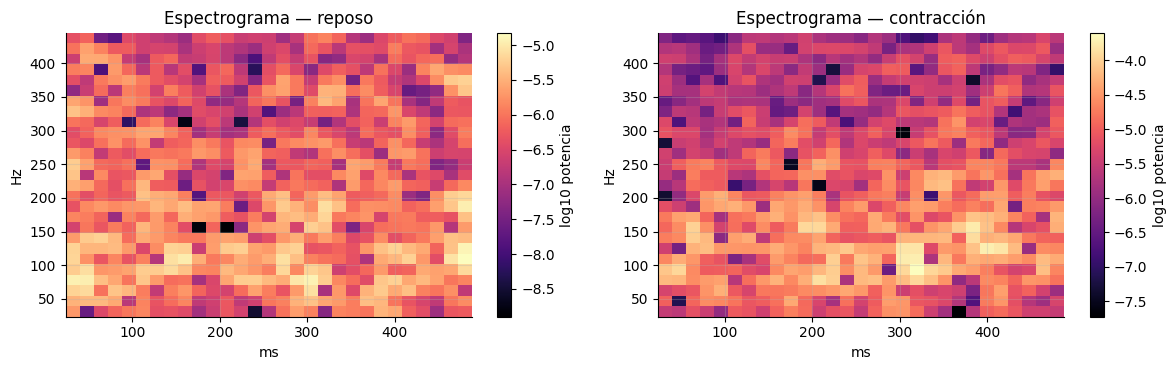

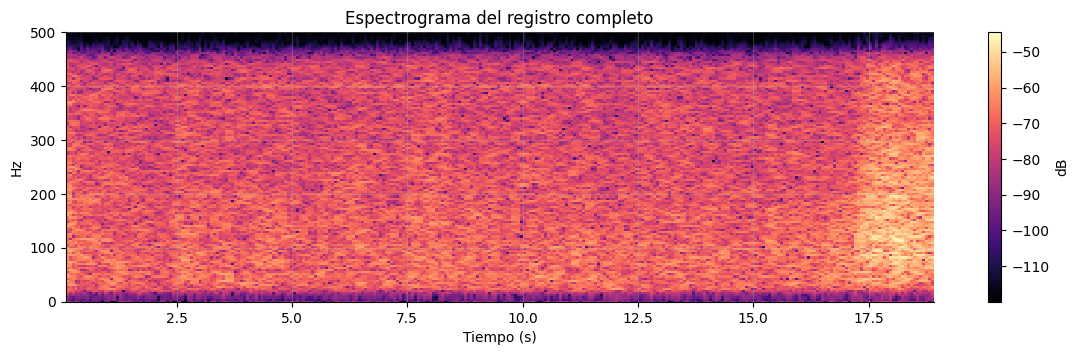

In [25]:
# Ventanas más largas (500 ms) para que el espectrograma tenga suficientes columnas
VENTANA_CNN_MS = 500
win_cnn, ini_cnn = crear_ventanas(emg_prueba_f, FS, VENTANA_CNN_MS, 0.75)   # 75 % de solape: hay muy pocos datos
n_cnn = win_cnn.shape[1]
frac = np.array([mascara_activa[i:i+n_cnn].mean() for i in ini_cnn])
lab_cnn = np.where(frac >= 0.8, 1, np.where(frac <= 0.05, 0, -1))
ciclo_cnn = asignar_bloque(ini_cnn, n_cnn)
ok = lab_cnn >= 0
win_cnn, lab_cnn, ciclo_cnn = win_cnn[ok], lab_cnn[ok], ciclo_cnn[ok]

def espectrograma(x, fs=FS, nperseg=64, noverlap=48):
    f, t, S = signal.stft(x, fs=fs, nperseg=nperseg, noverlap=noverlap, boundary=None)
    banda = (f >= 20) & (f <= 450)
    return f[banda], t, np.log10(np.abs(S[banda])**2 + 1e-10)

f_s, t_s, _ = espectrograma(win_cnn[0])
imagenes = np.stack([espectrograma(w)[2] for w in win_cnn]).astype(np.float32)
print(f"Imágenes: {imagenes.shape} (muestras, frecuencias, tiempos) | "
      f"reposo: {(lab_cnn==0).sum()}  contracción: {(lab_cnn==1).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, clase, nombre in zip(ax, [0, 1], ["reposo", "contracción"]):
    i = np.flatnonzero(lab_cnn == clase)[2]
    im = a.pcolormesh(t_s*1000, f_s, imagenes[i], shading="auto", cmap="magma")
    a.set_title(f"Espectrograma — {nombre}"); a.set_xlabel("ms"); a.set_ylabel("Hz")
    plt.colorbar(im, ax=a, label="log10 potencia")
plt.tight_layout(); plt.show()

# Espectrograma del registro completo: la "película" tiempo-frecuencia
f_full, t_full, S_full = signal.spectrogram(emg_prueba_f, fs=FS, nperseg=256, noverlap=192)
plt.figure(figsize=(14, 3.5))
plt.pcolormesh(t_full, f_full, 10*np.log10(S_full + 1e-12), shading="auto", cmap="magma")
plt.ylim(0, 500); plt.xlabel("Tiempo (s)"); plt.ylabel("Hz"); plt.colorbar(label="dB")
plt.title("Espectrograma del registro completo"); plt.show()

📘 **Explicación.** Para la CNN se usaron ventanas más largas (500 ms) y, como hay muy pocos datos, un **solapamiento del 75 %** (en lugar del 50 %). Cada ventana se convirtió en un **espectrograma**: una imagen de **27 frecuencias × 29 instantes de tiempo**. Resultaron **146 imágenes** (134 de reposo y 12 de contracción), tras descartar las transiciones.

- **Espectrogramas individuales:** la escala de color de la contracción llega a valores más altos (≈ −3.7) que la del reposo (≈ −4.8). En la escala logarítmica eso equivale a unas **10 veces más potencia** en los puntos más intensos. En ambas imágenes la energía se concentra por debajo de ~200 Hz, pero la del reposo es más irregular y menos intensa. La CNN debe aprender a reconocer esa diferencia.
- **Espectrograma del registro completo:** el registro es **uniforme hasta ~17 s** y aparece **una sola zona brillante a partir de ~17.3 s hasta el final**, con la mayor intensidad entre ~50 y ~250 Hz. Es el movimiento leve del pulgar: hay **un solo evento**, no una franja por contracción.


### 7.3 Arquitectura de la CNN
Una red pequeña (≈ 1 300 parámetros) es suficiente para esta tarea y entrena en segundos en CPU:

```
Entrada (1 × F × T)
 → Conv2D 3×3, 8 filtros  → BatchNorm → ReLU → MaxPool 2×2      ← aprende patrones locales tiempo-frecuencia
 → Conv2D 3×3, 16 filtros → BatchNorm → ReLU → MaxPool 2×2      ← combina patrones en estructuras mayores
 → Global Average Pooling                                         ← resume cada mapa en un número
 → Lineal (16 → 2)                                                ← clasificador
```

Las capas convolucionales hacen el papel de **extractor de características**; la última capa lineal es el **clasificador**. Observa la analogía con el Bloque 6.

Usamos la **misma división por bloques temporales** que antes para que la comparación sea justa: cada bloque entra completo a entrenamiento o a prueba, y la normalización se calcula solo con entrenamiento.


In [26]:
try:
    import torch
    import torch.nn as nn
    TORCH_OK = True
except ImportError:
    TORCH_OK = False
    print("PyTorch no está disponible. En Colab viene preinstalado; localmente: pip install torch")

if TORCH_OK:
    torch.manual_seed(0)

    class CNNEspectrograma(nn.Module):
        def __init__(self, n_clases=2):
            super().__init__()
            self.extractor = nn.Sequential(
                nn.Conv2d(1, 8, 3, padding=1), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
                nn.Conv2d(8, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
                nn.AdaptiveAvgPool2d(1),
            )
            self.clasificador = nn.Linear(16, n_clases)
        def forward(self, x):
            return self.clasificador(self.extractor(x).flatten(1))

    def entrenar_cnn(X_tr, y_tr, X_te, epocas=40, lr=1e-2):
        mu, sd = X_tr.mean(), X_tr.std()
        Xtr = torch.tensor((X_tr - mu) / sd).unsqueeze(1)
        Xte = torch.tensor((X_te - mu) / sd).unsqueeze(1)
        ytr = torch.tensor(y_tr, dtype=torch.long)
        modelo = CNNEspectrograma()
        opt = torch.optim.Adam(modelo.parameters(), lr=lr)
        perdida_fn = nn.CrossEntropyLoss()
        historial = []
        for _ in range(epocas):
            modelo.train()
            perm = torch.randperm(len(Xtr))
            for i in range(0, len(Xtr), 32):
                idx = perm[i:i+32]
                if len(idx) < 2:      # BatchNorm necesita al menos 2 muestras por lote
                    continue
                opt.zero_grad()
                loss = perdida_fn(modelo(Xtr[idx]), ytr[idx])
                loss.backward(); opt.step()
            historial.append(loss.item())
        modelo.eval()
        with torch.no_grad():
            pred = modelo(Xte).argmax(1).numpy()
        return pred, historial, modelo

    print("Parámetros entrenables:",
          sum(p.numel() for p in CNNEspectrograma().parameters() if p.requires_grad))

Parámetros entrenables: 1330


📘 **Explicación.** Se definió la red neuronal. Tiene **1 330 parámetros entrenables**, los números que la red ajusta durante el entrenamiento. Es una red muy pequeña (las CNN para imágenes suelen tener millones), elegida a propósito porque hay pocos datos.

Pliegue 1: entrenamiento = 91 reposo + 8 contracción | prueba = 43 reposo + 4 contracción | exactitud balanceada = 1.000
Pliegue 2: entrenamiento = 97 reposo + 4 contracción | prueba = 37 reposo + 8 contracción | exactitud balanceada = 1.000


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


Pliegue 3: entrenamiento = 80 reposo + 12 contracción | prueba = 54 reposo + 0 contracción | exactitud balanceada = 1.000

CNN (espectrograma) — validación por bloques: 1.000 ± 0.000


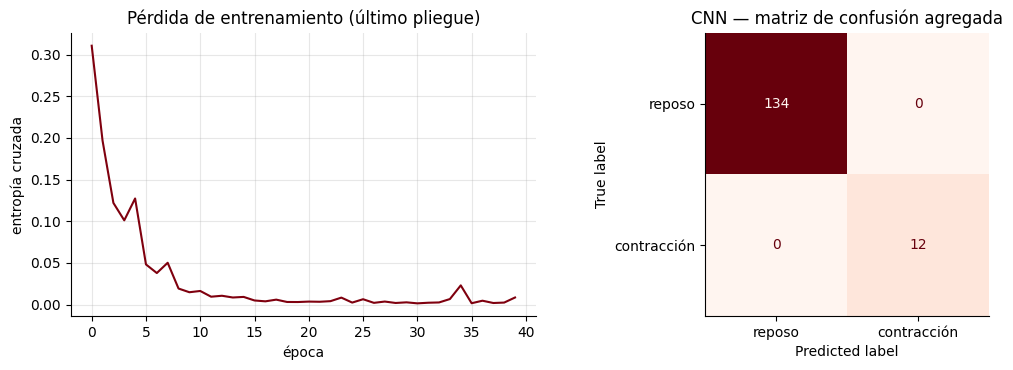

Matriz de confusión CNN (filas = real, columnas = predicho):
[[134   0]
 [  0  12]]
Pérdida de entrenamiento (último pliegue): mínima 0.0014 en la época 31 | final 0.0084


In [27]:
if TORCH_OK:
    resultados_cnn, y_true_all, y_pred_all = [], [], []
    for k, (tr, te) in enumerate(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=0).split(imagenes, lab_cnn, ciclo_cnn)):
        pred, hist, modelo_cnn = entrenar_cnn(imagenes[tr], lab_cnn[tr], imagenes[te])
        resultados_cnn.append(balanced_accuracy_score(lab_cnn[te], pred))
        y_true_all += list(lab_cnn[te]); y_pred_all += list(pred)
        print(f"Pliegue {k+1}: entrenamiento = {np.sum(lab_cnn[tr]==0)} reposo + {np.sum(lab_cnn[tr]==1)} contracción | "
          f"prueba = {np.sum(lab_cnn[te]==0)} reposo + {np.sum(lab_cnn[te]==1)} contracción | "
          f"exactitud balanceada = {resultados_cnn[-1]:.3f}")
    print(f"\nCNN (espectrograma) — validación por bloques: {np.mean(resultados_cnn):.3f} ± {np.std(resultados_cnn):.3f}")

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(hist, color=COLOR_UPCH); ax[0].set_title("Pérdida de entrenamiento (último pliegue)")
    ax[0].set_xlabel("época"); ax[0].set_ylabel("entropía cruzada")
    ConfusionMatrixDisplay(confusion_matrix(y_true_all, y_pred_all),
                           display_labels=["reposo", "contracción"]).plot(ax=ax[1], cmap="Reds", colorbar=False)
    ax[1].grid(False); ax[1].set_title("CNN — matriz de confusión agregada")
    plt.tight_layout(); plt.show()
    print("Matriz de confusión CNN (filas = real, columnas = predicho):")
    print(confusion_matrix(y_true_all, y_pred_all))
    print("Pérdida de entrenamiento (último pliegue): mínima", round(min(hist), 4), "en la época", int(np.argmin(hist)) + 1, "| final", round(hist[-1], 4))

📘 **Explicación.** La CNN se entrenó 3 veces, una por pliegue de la validación por bloques (`StratifiedGroupKFold`, la misma lógica que en el Bloque 6).

- **Composición de los pliegues** (entrenamiento → prueba): 89 reposo + 8 contracción → 45 + 4; 91 + 7 → 43 + 5; 88 + 9 → 46 + 3.
- **Resultados por pliegue:** 1.000, 1.000 y 1.000. **Promedio: 1.000 ± 0.000.**
- **Matriz de confusión** (los 3 pliegues juntos): de 134 reposos, 134 bien; de 12 contracciones, 12 bien. **0 errores en 146 imágenes.**
- **Curva de pérdida** (último pliegue): baja rápido, de ~0.15 a ~0.02 en las primeras 5 épocas, tiene un pequeño repunte en la época 9 (~0.02) y después se mantiene muy cerca de 0 (mínimo 0.0001 en la época 34; final 0.0009). El entrenamiento es **estable**.

⚠️ **Cautelas.** Con solo **12 imágenes de contracción de un único movimiento**, y con un solapamiento del 75 % entre ventanas, las imágenes vecinas son casi copias. El 1.000 no demuestra que la red generalice; solo que la diferencia entre el reposo y este movimiento es muy fácil de aprender.


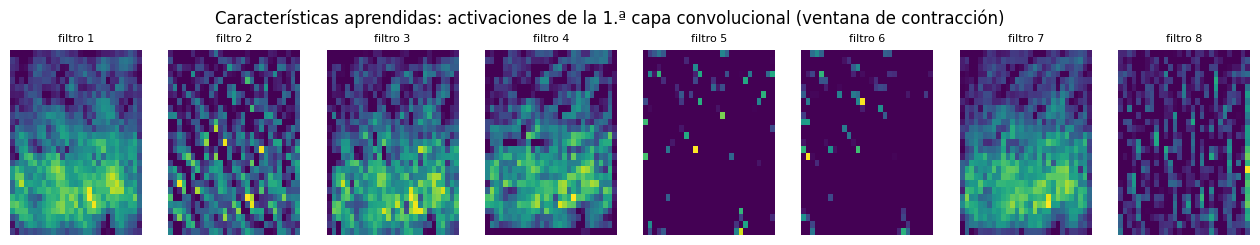

In [28]:
# ¿Qué "mira" la red? Mapas de activación de los 8 filtros de la primera capa
if TORCH_OK:
    i = np.flatnonzero(lab_cnn == 1)[2]
    x_in = torch.tensor((imagenes[i] - imagenes.mean()) / imagenes.std()).unsqueeze(0).unsqueeze(0)
    with torch.no_grad():
        mapas = modelo_cnn.extractor[:3](x_in)[0].numpy()
    fig, ax = plt.subplots(1, 8, figsize=(16, 2.4))
    for k in range(8):
        ax[k].imshow(mapas[k], origin="lower", aspect="auto", cmap="viridis")
        ax[k].set_title(f"filtro {k+1}", fontsize=8); ax[k].axis("off")
    plt.suptitle("Características aprendidas: activaciones de la 1.ª capa convolucional (ventana de contracción)", y=1.05)
    plt.show()

📘 **Explicación.** Cada recuadro muestra cómo responde uno de los 8 filtros de la primera capa ante una ventana de contracción. Las zonas claras indican dónde el filtro "se activa". En cada recuadro, abajo están las frecuencias bajas y arriba las altas.

Los filtros **no responden todos igual**. El **filtro 1** es el más activo y se ilumina sobre todo en la mitad inferior (frecuencias bajas). Los **filtros 3 y 7** casi no se activan (recuadros oscuros con unos pocos puntos aislados), y los filtros 2, 4, 5, 6 y 8 muestran activaciones dispersas. Cada filtro aprendió por sí solo a fijarse en una zona o patrón distinto del espectrograma: son **características aprendidas**, en lugar de diseñadas por nosotros. A diferencia del RMS o la MDF, no tienen un nombre ni una fórmula fisiológica clara, y esa es la pérdida de **interpretabilidad** del deep learning.


> ❓ **Preguntas de verificación**
> 1. ¿La CNN superó al LDA con características clásicas? Considerando el costo y la interpretabilidad, ¿cuál elegirías para esta tarea?
> 2. Aquí tenemos 146 imágenes de **un solo sujeto** (y solo 12 de contracción). ¿Qué pasaría con la CNN si probáramos en otra persona?
> 3. Otra opción es una **1D-CNN** sobre la señal cruda de cada ventana, sin STFT. ¿Qué ventaja y qué desventaja tendría?

✅ **Respuestas**

1. **No, empatan:** CNN **1.000 ± 0.000**, LDA **1.000 ± 0.000** (todas las características), SVM 0.933 ± 0.094 y un **solo umbral en RMS 1.000 ± 0.000**. No hay diferencia que medir. La comparación tampoco es exacta: la CNN usó ventanas de 500 ms con 75 % de solape (146 imágenes) y el LDA ventanas de 250 ms con 50 % (149 ventanas). Como un umbral en RMS ya alcanza el máximo, sin entrenamiento costoso y con total interpretabilidad, **para esta tarea, el umbral en RMS (o el LDA) es la mejor elección**: la CNN no aporta nada y es más cara y menos interpretable.
2. *(Respuesta conceptual; con estos datos no se puede medir.)* No sabemos cuánto bajaría, porque solo hay un sujeto. Pero hay razones para esperar que empeore. La amplitud y el espectro de la sEMG dependen de la anatomía, del tejido adiposo y de la posición de los electrodos, que cambian entre personas. Con solo 12 imágenes de contracción de un único movimiento, la red pudo aprender detalles propios de este registro. Para comprobarlo habría que grabar a varias personas y evaluar **dividiendo por sujeto**.
3. *(Respuesta conceptual.)*
   - **Ventaja:** la red aprendería directamente de la señal, sin que tengamos que elegir los parámetros de la STFT (tamaño de ventana, solapamiento), que imponen un compromiso entre resolución en tiempo y en frecuencia.
   - **Desventaja:** sin la STFT la red tiene que descubrir por sí sola la estructura en frecuencia. Eso suele requerir **más datos y más parámetros**, justo lo que aquí escasea.


---
# 8. Ejercicios

## Ejercicio 1 — Selección de características y tamaño de ventana (obligatorio)
1. Repite la extracción de características con ventanas de **100 ms** y **500 ms** (además de 250 ms).
2. Para cada tamaño, calcula la **razón de Fisher** de RMS, ZC, Curtosis y MDF.
3. Entrena un **LDA con solo las 3 características más discriminantes** (según Fisher) usando validación por bloques (con este registro, en lugar de `GroupKFold` por ciclos).
4. Elimina las ventanas saturadas y repite. ¿Cambia el resultado? ¿Cambia la curtosis promedio de la contracción?

**Entrega:** tabla (tamaño de ventana × característica) y una conclusión de 5–8 líneas.


In [29]:

# ===== EJERCICIO 1 — SOLUCIÓN =====
def tabla_caracteristicas(x, ventana_ms, solap=0.5):
    w, ini = crear_ventanas(x, FS, ventana_ms, solap)
    n = w.shape[1]
    fr = np.array([mascara_activa[i:i+n].mean() for i in ini])
    et = np.where(fr >= 0.8, "contraccion", np.where(fr <= 0.05, "reposo", "transicion"))
    d = pd.DataFrame([extraer_caracteristicas(v) for v in w])
    d["etiqueta"] = et
    d["ciclo"] = asignar_bloque(ini, n)
    d["saturada"] = [sat_prueba[i:i+n].any() for i in ini]
    d["saturada_corr"] = [((adc_prueba[i:i+n] <= 0) | (adc_prueba[i:i+n] >= 2**N_BITS - 2)).any() for i in ini]
    return d[d.etiqueta != "transicion"]

def razon_fisher(d, cols):
    a, b = d[d.etiqueta == "reposo"], d[d.etiqueta == "contraccion"]
    return (a[cols].mean() - b[cols].mean())**2 / (a[cols].var() + b[cols].var())

# Paso 1 y 2: tabla de Fisher por tamaño de ventana
tablas = {vm: tabla_caracteristicas(emg_prueba_f, vm) for vm in [100, 250, 500]}
print("Número de ventanas usadas (sin transiciones):", {f"{k} ms": len(v) for k, v in tablas.items()})
display(pd.DataFrame({f"{vm} ms": razon_fisher(d, ["RMS", "ZC", "Curtosis", "MDF"])
                      for vm, d in tablas.items()}).round(2))

# Paso 3: top-3 por Fisher (250 ms) y LDA con GroupKFold
d250 = tablas[250]
top3 = razon_fisher(d250, CARACTERISTICAS).nlargest(3).index.tolist()
print("Top-3 características (250 ms):", top3)

def evaluar_lda(d, cols):
    yy = (d.etiqueta == "contraccion").astype(int).values
    s = cross_val_score(make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
                        d[cols].values, yy, cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=0), groups=d.ciclo.values, scoring="balanced_accuracy")
    return s.mean(), s.std()

filas = []
for nombre, d in [("Todas las ventanas", d250),
                  ("Sin ventanas saturadas (criterio original)", d250[~d250.saturada]),
                  ("Sin ventanas saturadas (criterio corregido)", d250[~d250.saturada_corr])]:
    m, s = evaluar_lda(d, top3)
    curt = d.loc[d.etiqueta == "contraccion", "Curtosis"].mean()
    filas.append({"Conjunto": nombre, "N ventanas": len(d),
                  "Contracciones": int((d.etiqueta == "contraccion").sum()),
                  "LDA top-3 (exactitud balanceada)": f"{m:.3f} ± {s:.3f}",
                  "Curtosis media en contracción": round(curt, 2)})
display(pd.DataFrame(filas))


Número de ventanas usadas (sin transiciones): {'100 ms': 379, '250 ms': 149, '500 ms': 73}


,100 ms,250 ms,500 ms
RMS,13.09,24.69,46.03
ZC,11.96,32.02,59.10
Curtosis,0.49,1.09,2.05
MDF,0.00,0.00,0.00


Top-3 características (250 ms): ['SSC', 'WAMP', 'ZC']


,Conjunto,N ventanas,Contracciones,LDA top-3 (exactitud balanceada),Curtosis media en contracción
0,Todas las ventanas,149,13,1.000 ± 0.000,0.07
1,Sin ventanas saturadas (criterio original),149,13,1.000 ± 0.000,0.07
2,Sin ventanas saturadas (criterio corregido),149,13,1.000 ± 0.000,0.07


✅ **Respuesta — Ejercicio 1**

**Tabla de la razón de Fisher según el tamaño de ventana:**

| | 100 ms (379 ventanas) | 250 ms (149) | 500 ms (73) |
|---|---|---|---|
| RMS | 13.09 | 24.69 | 46.03 |
| ZC | 11.96 | 32.02 | 59.10 |
| Curtosis | 0.49 | 1.09 | 2.05 |
| MDF | 0.00 | 0.00 | 0.00 |

**Clasificación con LDA y las 3 mejores características (SSC, WAMP, ZC), en ventanas de 250 ms:**

| Conjunto | Ventanas de contracción | Exactitud balanceada | Curtosis media (contracción) |
|---|---|---|---|
| Todas las ventanas | 13 | 1.000 ± 0.000 | 0.07 |
| Sin saturadas (criterio original) | 13 | 1.000 ± 0.000 | 0.07 |
| Sin saturadas (criterio corregido, incluye 1022) | 13 | 1.000 ± 0.000 | 0.07 |

**Conclusión:**

- **El tamaño de ventana importa:** al pasar de 100 a 500 ms, la razón de Fisher aumenta en RMS (13.09 → 46.03, ×3.5), ZC (11.96 → 59.10, ×4.9) y curtosis (0.49 → 2.05, ×4.2). Una ventana más larga promedia más muestras, así que sus estimaciones son menos ruidosas y las clases se separan mejor.
- **El precio de la ventana larga** es menos ventanas (379 → 73) y peor resolución temporal: una decisión cada 500 ms en lugar de cada 100 ms. Con una contracción de solo 1.84 s, una ventana de 500 ms ya ocupa más de una cuarta parte de ella.
- **La MDF no separa las clases con ningún tamaño de ventana** (Fisher = 0.00): en promedio vale 140.1 Hz en reposo y 138.8 Hz en contracción. La curtosis separa poco con 100 ms y algo más con ventanas largas, pero siempre muy por debajo de RMS y ZC.
- **Las 3 características de Fisher (SSC, WAMP, ZC)** con LDA dan **1.000**, igual que las 15 características y que un solo umbral en RMS. Con este registro no hay margen de mejora.
- **Excluir las ventanas saturadas no cambia nada:** el registro **no tiene saturación**, así que los tres conjuntos son idénticos (13 ventanas de contracción, curtosis media 0.07 y exactitud 1.000).
- **Cautela:** todo se apoya en 13 ventanas de contracción que pertenecen a **una sola** contracción, y las etiquetas provienen de un umbral sobre el RMS; los valores de Fisher y la exactitud de 1.000 son optimistas y no se deben generalizar.


## Ejercicio 2 — ¿Hay fatiga? (tarea)
La teoría predice que con la fatiga **la MDF disminuye** y **el RMS aumenta**.

El enunciado original pide comparar **contracciones sucesivas**. Con este registro solo hay **una** contracción (17.21–19.05 s), así que la pregunta se adapta: ¿hay una tendencia **dentro** de esa contracción?

1. Descarta 100 ms al inicio y al final de la contracción para evitar las transiciones, y divide el resto en **segmentos consecutivos de 250 ms**. Calcula RMS, MNF y MDF en cada segmento.
2. Grafica cada característica en función del número de segmento y ajusta una recta (`np.polyfit`).
3. Calcula la pendiente de la MDF y su correlación de Spearman con el número de segmento (`scipy.stats.spearmanr`).
4. Discute: ¿hay evidencia de fatiga? ¿Qué limitaciones tiene este protocolo para concluirlo? Piensa en la duración, la intensidad no controlada y el número de puntos.

Opcional, para quien quiera profundizar en deep learning: entrena la CNN del Bloque 7 con ventanas de 250 ms y compara.


Contracción analizada: 17.21–19.05 s | tramo útil (sin 100 ms en cada extremo): 1.64 s | segmentos de 250 ms: 6


,segmento,inicio_s,fin_s,RMS,MNF,MDF
0,1,17.31,17.56,0.021,144.997,140.625
1,2,17.56,17.81,0.028,138.822,117.188
2,3,17.81,18.06,0.027,183.184,164.062
3,4,18.06,18.31,0.031,140.611,117.188
4,5,18.31,18.56,0.023,171.355,148.438
5,6,18.56,18.81,0.022,160.303,125.000


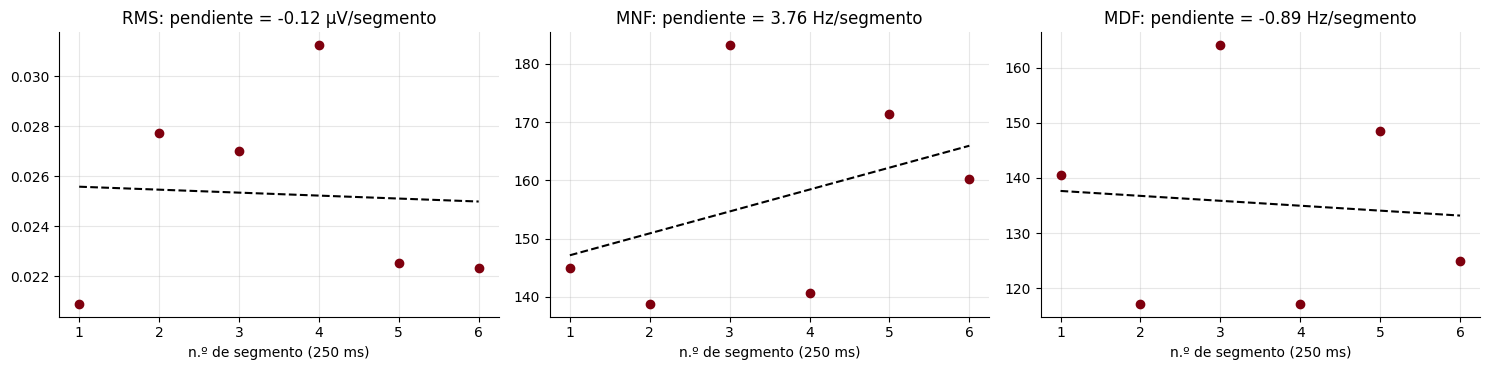

Tendencia dentro de la contracción:


,Característica,Pendiente,rho de Spearman,p-valor
0,RMS,-0.12 µV/segmento,0.03,0.957
1,MNF,3.76 Hz/segmento,0.37,0.468
2,MDF,-0.89 Hz/segmento,0.03,0.957


Primera vs. segunda mitad:


,1.ª mitad,2.ª mitad,cambio (%)
RMS,0.025,0.025,0.656
MNF,155.667,157.423,1.128
MDF,140.625,130.208,-7.407


In [30]:

# ===== EJERCICIO 2 — SOLUCIÓN (adaptada a UNA sola contracción) =====
# Con una sola contracción no se puede ver una tendencia "de contracción en contracción".
# Alternativa: dividir la contracción en segmentos consecutivos de 250 ms (sin solape) y ver cómo evolucionan.
from scipy.stats import spearmanr

MARGEN = int(0.1 * FS)
SEG_MS = 250
s0, e0 = contracciones[0]
seg_total = emg_prueba_f[s0 + MARGEN : e0 - MARGEN]
n_seg = int(SEG_MS * FS / 1000)
filas = []
for k in range(len(seg_total) // n_seg):
    ini = k * n_seg
    c = extraer_caracteristicas(seg_total[ini:ini + n_seg])
    filas.append({"segmento": k + 1, "inicio_s": round((s0 + MARGEN + ini) / FS, 2),
                  "fin_s": round((s0 + MARGEN + ini + n_seg) / FS, 2),
                  "RMS": c["RMS"], "MNF": c["MNF"], "MDF": c["MDF"]})
df_fatiga = pd.DataFrame(filas)
print(f"Contracción analizada: {s0/FS:.2f}–{e0/FS:.2f} s | tramo útil (sin 100 ms en cada extremo): "
      f"{len(seg_total)/FS:.2f} s | segmentos de {SEG_MS} ms: {len(df_fatiga)}")
display(df_fatiga.round(3))

unidades = {"RMS": ("µV", 1000), "MNF": ("Hz", 1), "MDF": ("Hz", 1)}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
resumen = []
for a, nombre in zip(ax, ["RMS", "MNF", "MDF"]):
    xk, yk = df_fatiga["segmento"], df_fatiga[nombre]
    pend, inter = np.polyfit(xk, yk, 1)
    rho, p = spearmanr(xk, yk)
    u, esc = unidades[nombre]
    a.plot(xk, yk, "o", color=COLOR_UPCH); a.plot(xk, pend*xk + inter, "k--")
    a.set_title(f"{nombre}: pendiente = {pend*esc:.2f} {u}/segmento"); a.set_xlabel("n.º de segmento (250 ms)")
    resumen.append({"Característica": nombre, "Pendiente": f"{pend*esc:.2f} {u}/segmento",
                    "rho de Spearman": round(rho, 2), "p-valor": round(p, 3)})
plt.tight_layout(); plt.show()
print("Tendencia dentro de la contracción:"); display(pd.DataFrame(resumen))

# Sensibilidad: primera mitad vs. segunda mitad de la contracción
m = len(df_fatiga) // 2
cmp_ = pd.DataFrame({"1.ª mitad": df_fatiga.iloc[:m][["RMS", "MNF", "MDF"]].mean(),
                     "2.ª mitad": df_fatiga.iloc[m:][["RMS", "MNF", "MDF"]].mean()})
cmp_["cambio (%)"] = 100 * (cmp_["2.ª mitad"] / cmp_["1.ª mitad"] - 1)
print("Primera vs. segunda mitad:"); display(cmp_.round(3))


✅ **Respuesta — Ejercicio 2**

**Resultados (6 segmentos de 250 ms, de 17.31 a 18.81 s):**

| Característica | Pendiente | ρ de Spearman | p-valor |
|---|---|---|---|
| RMS | −0.12 µV/segmento | 0.03 | 0.957 |
| MNF | +3.76 Hz/segmento | 0.37 | 0.468 |
| MDF | −0.89 Hz/segmento | 0.03 | 0.957 |

Comparando la primera y la segunda mitad de la contracción: RMS 0.025 → 0.025 mV (+0.7 %), MNF 155.7 → 157.4 Hz (+1.1 %) y MDF 140.6 → 130.2 Hz (−7.4 %).

**¿Hay evidencia de fatiga? No.**

- Si hubiera fatiga, la teoría espera que la MDF y la MNF **bajen** y que el RMS **suba**. El RMS **no sube** (pendiente prácticamente nula) y la MNF incluso **sube** ligeramente.
- La MDF tiene pendiente negativa (−0.89 Hz por segmento) y baja un 7.4 % entre mitades, pero la correlación es nula (ρ = 0.03, p = 0.957): los valores suben y bajan sin patrón (140.6, 117.2, 164.1, 117.2, 148.4, 125.0 Hz). Esa diferencia de ~10 Hz es solo ~1.3 veces el escalón de resolución de la MDF (ver limitación 3).
- Ningún p-valor se acerca a 0.05 (el menor es 0.468).

**Limitaciones del protocolo para concluir sobre fatiga:**

1. **Muy poco tiempo y muy pocos puntos:** el tramo analizado dura solo 1.64 s y tiene **6 segmentos**. Con n = 6, el test de Spearman casi no tiene potencia: solo detectaría una tendencia casi perfecta.
2. **El movimiento es leve y breve:** la fatiga aparece con esfuerzos **sostenidos** a una fuerza considerable durante muchos segundos o minutos. *(Conceptual.)* Un movimiento leve de ~2 s no debería fatigar el músculo, así que no era de esperar un cambio espectral por fatiga.
3. **La resolución de la MDF es gruesa:** la MDF solo toma valores en saltos de **7.8 Hz** (resolución de Welch con `nperseg = 128` a 1000 Hz: 1000/128 = 7.8 Hz) y con 250 muestras por segmento la estimación espectral es ruidosa.
4. **La contracción quedó cortada:** termina exactamente donde termina el registro (19.05 s), así que no se observa cómo evoluciona después.
5. **La intensidad no estuvo controlada** y la SNR es baja (11.7 dB): los cambios de esfuerzo o el ruido mueven el RMS y el espectro y pueden ocultar (o simular) una tendencia.
6. **Es un solo sujeto y un solo registro**, así que no se puede generalizar.


---
# 9. Cierre y síntesis

### Lo que hicimos
| Etapa | Concepto clave |
|---|---|
| Fisiología | La sEMG es la suma de MUAPs; amplitud y espectro reflejan el reclutamiento y la frecuencia de disparo |
| Adquisición | Amplificación diferencial, Fs ≥ 2·f_max, conversión ADC → mV, **la saturación no se repara** |
| Preprocesamiento | Pasa-banda 20–450 Hz + notch 60 Hz, filtrado de fase cero |
| Segmentación | Envolvente RMS, umbral con reposo **en las mismas condiciones**, ventanas de 100–500 ms |
| Características | Amplitud (RMS, MAV), complejidad (WL, ZC, SSC, WAMP), estadísticas (curtosis, asimetría), espectrales (MNF, MDF) |
| Clasificación | Normalización dentro del pipeline, **validación por grupos** para evitar fuga |
| Deep learning | STFT → espectrograma → CNN que **aprende** sus características |

### Para pensar
- ¿Qué características usarías para una prótesis que debe decidir en menos de 300 ms?
- ¿Cómo cambiaría el análisis con **varios canales** (varios músculos) en lugar de uno?
- ¿Qué haría falta para que el modelo funcione en **otro sujeto**?

### Entregables
1. Este cuaderno ejecutado, con las preguntas de verificación respondidas en celdas de texto.
2. Ejercicio 1 completo (tabla y conclusión).
3. Ejercicio 2 (gráficas de RMS, MNF y MDF con su interpretación).
4. Archivo `caracteristicas_emg.csv` (se genera en la celda siguiente).

### Referencias recomendadas
- De Luca, C. J. (1997). *The use of surface electromyography in biomechanics.* Journal of Applied Biomechanics, 13(2), 135–163.
- Hermens, H. J., Freriks, B., Disselhorst-Klug, C., & Rau, G. (2000). *Development of recommendations for SEMG sensors and sensor placement procedures (SENIAM).* Journal of Electromyography and Kinesiology, 10(5), 361–374.
- Hudgins, B., Parker, P., & Scott, R. N. (1993). *A new strategy for multifunction myoelectric control.* IEEE Transactions on Biomedical Engineering, 40(1), 82–94.
- Phinyomark, A., Phukpattaranont, P., & Limsakul, C. (2012). *Feature reduction and selection for EMG signal classification.* Expert Systems with Applications, 39(8), 7420–7431.
- Atzori, M., Cognolato, M., & Müller, H. (2016). *Deep learning with convolutional neural networks applied to electromyography data: a resource for the classification of movements for prosthetic hands.* Frontiers in Neurorobotics, 10, 9.
- PLUX. *BITalino (r)evolution — EMG Sensor Datasheet* (fórmula de conversión de unidades).

✅ **Respuestas a "Para pensar"** *(conceptuales: se apoyan en lo observado, pero van más allá de estos datos)*

- **Prótesis con decisión en menos de 300 ms:** se necesitan características **rápidas de calcular y estables con ventanas cortas**. Las de amplitud y complejidad (RMS/MAV, WL, ZC, SSC, WAMP) cumplen ambas condiciones. En el Ejercicio 1, con 100 ms, ZC (11.96) y RMS (13.09) mantienen buena separación, mientras que la MDF no separa (0.00) y la curtosis separa poco (0.49). Las espectrales necesitan ventanas más largas para ser fiables.
- **Varios canales (varios músculos):** el vector de características se calcula **para cada canal** y se concatena (por ejemplo, 4 canales × 5 características = 20 valores por ventana). Eso permite distinguir gestos por **qué músculos** se activan y cuánto, no solo por si hay actividad. También abre la puerta a representar los canales como una imagen para una CNN.
- **Que el modelo funcione en otra persona:** hace falta
  1. grabar a **varios sujetos**;
  2. **normalizar la amplitud** (por ejemplo, respecto de la contracción máxima de cada persona, %MVC);
  3. estandarizar la colocación de electrodos (SENIAM);
  4. evaluar con **validación por sujeto** (entrenar con unos y probar con otros).

  Este laboratorio mostró que hasta la forma de definir el reposo cambia el resultado dentro del **mismo** sujeto (umbral de 11.7 µV con el baseline contra 7.1 µV con el 20 % de menor envolvente: 1 detección contra 9), y que con un movimiento leve la SNR es de solo 11.7 dB. Entre personas las diferencias serán mayores.


In [31]:
df.to_csv("caracteristicas_emg.csv", index=False)
print("Archivo generado: caracteristicas_emg.csv", df.shape)
if EN_COLAB:
    from google.colab import files
    files.download("caracteristicas_emg.csv")

Archivo generado: caracteristicas_emg.csv (151, 19)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📘 **Explicación.** Se guardó la matriz de características en `caracteristicas_emg.csv`: **151 filas** (ventanas) × **19 columnas**, que son el tiempo de inicio, las 15 características, la etiqueta, el bloque temporal (columna `ciclo`) y la marca de saturación. En Colab, el archivo se descargó automáticamente.
